# PROJECT 2

## <h1 align="center">1. CarDekho Used Car Price Prediction</h1>
## <h2 style="text-align:center;">End-to-End Machine Learning Project</h2>

## 2 Process Flow of Project

## Process Flow of Project

1. Understanding Problem Statement
2. Getting System Ready
3. Data Collection
4. Understanding the Data – Data Eyeballing & Data Description
5. Exploratory Data Analysis (EDA)
   1. Univariate Analysis
   2. Bivariate Analysis
   3. Multivariate Analysis
6. Insights from Data Visualization
7. Feature Engineering
8. Model Building & Evaluation
9. Selection of Best Model & Hyperparameter Tuning
10. Generating Pickle File

# 3 Understanding Problem Statement
## 3.1 Problem Statement

The used car market in India is a dynamic and ever-changing landscape. Prices can fluctuate widely based on a variety of factors, including the make and model of the car, its mileage, its condition, and current market conditions. As a result, it can be difficult for sellers to accurately price their cars.

## 3.2 Approach

We propose to develop a Machine Learning model that can predict the price of a used car based on its features. The model will be trained on a dataset of used cars that have been sold on CarDekho.com in India. The trained model can then be used to predict the price of any used car based on its input features.

## 3.3 Objective

To build a suitable Machine Learning model for used car price prediction.

## 3.4 Benefits

The benefits of this solution include:

Sellers will be able to more accurately price their cars, helping them sell faster and at a better price.
Buyers will be able to find cars that are priced more competitively.
The overall used car market in India will become more efficient.

We believe that this project has the potential to make a significant impact on the used car market in India. We are excited to work on this project and demonstrate how machine learning can improve the accuracy and efficiency of used car price prediction.

# 4. Import Data and Required Packages

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
from six.moves import urllib

warnings.filterwarnings("ignore")
%matplotlib inline

# 5. Data Collection

In [32]:
import os
import urllib.request
import pandas as pd

download_dir = "./data/"

download_url = "https://raw.githubusercontent.com/shrutisbhosale14/Project_CarDekho-Data-Analysis/main/Cardekho_Dataset.csv"
os.makedirs(download_dir, exist_ok=True)

filename = os.path.basename(download_url)

download_file_path = os.path.join(download_dir, filename)

urllib.request.urlretrieve(download_url, download_file_path)

print('-' * 100)
print('Data with name ' + filename + ' Downloaded at ' + download_file_path)
print('-' * 100)

df = pd.read_csv(download_file_path, index_col=[0])

----------------------------------------------------------------------------------------------------
Data with name Cardekho_Dataset.csv Downloaded at ./data/Cardekho_Dataset.csv
----------------------------------------------------------------------------------------------------


In [127]:
df.head()

,car_name,brand,model,min_cost_price,max_cost_price,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,40000,39500000,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,40000,39500000,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,40000,39500000,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,40000,39500000,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,40000,39500000,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [128]:
df['min_cost_price'] = df['selling_price'].min()
df['max_cost_price'] = df['selling_price'].max()

In [129]:
print('The size of Dataframe is:',df.shape)
print('-'*100)
print('The Column Name,Record Count and Data Types are as follows:')
df.info()
print('-'*100)

The size of Dataframe is: (15411, 15)
----------------------------------------------------------------------------------------------------
The Column Name,Record Count and Data Types are as follows:
<class 'pandas.core.frame.DataFrame'>
Index: 15411 entries, 0 to 19543
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   min_cost_price     15411 non-null  int64  
 4   max_cost_price     15411 non-null  int64  
 5   vehicle_age        15411 non-null  int64  
 6   km_driven          15411 non-null  int64  
 7   seller_type        15411 non-null  object 
 8   fuel_type          15411 non-null  object 
 9   transmission_type  15411 non-null  object 
 10  mileage            15411 non-null  float64
 11  engine             15411 non-null  int64  
 12  max_power          1

In [130]:
#defining numerical & categorical columns
numeric_features=[feature for feature in df.columns if df[feature].dtype !='O']
categorical_features=[feature for feature in df.columns if df[feature].dtype =='O']

print('we have {} numerical features: {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features :{}'.format(len(categorical_features),categorical_features,categorical_features))
      

we have 9 numerical features: ['min_cost_price', 'max_cost_price', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

We have 6 categorical features :['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']


# 6. Data Description

In [131]:
# Finding Null values
print('Missing Value Presence in different columns of Dataframe are as folows:')
print('_'*100)

total=df.isnull().sum().sort_values(ascending=False)
percent=(df.isnull().sum()/df.isnull().count()*
         100).sort_values(ascending=False)
pd.concat([total,percent],axis=1, keys=['Total','Percent'])



Missing Value Presence in different columns of Dataframe are as folows:
____________________________________________________________________________________________________


,Total,Percent
car_name,0,0.0
brand,0,0.0
model,0,0.0
min_cost_price,0,0.0
max_cost_price,0,0.0
vehicle_age,0,0.0
km_driven,0,0.0
seller_type,0,0.0
fuel_type,0,0.0
transmission_type,0,0.0


In [132]:
print('Summary Statistics of numerical features for dataframe are as follows:')
print('-'*100)
df.describe(include='object')

Summary Statistics of numerical features for dataframe are as follows:
----------------------------------------------------------------------------------------------------


,car_name,brand,model,seller_type,fuel_type,transmission_type
count,15411,15411,15411,15411,15411,15411
unique,121,32,120,3,5,2
top,Hyundai i20,Maruti,i20,Dealer,Petrol,Manual
freq,906,4992,906,9539,7643,12225


In [142]:
# checkig mis spelt and typo error
print('-'*125)
print('Checking records for mis spell,typo error')
print('-'*125)

print("'car_name' variable have {} unique category:\n{}\n".format(df['car_name'].nunique(),df['car_name'].unique()))
print('-'*125)

print("'brand' variable have {} unique category:\n{}\n".format(df['brand'].nunique(),df['brand'].unique()))
print('-'*125)

print("'model' variable have {} unique category:\n{}\n".format(df['model'].nunique(),df['model'].unique()))
print('-'*125)

print("'seller_type' variable have {} unique category:\n{}\n".format(df['seller_type'].nunique(),df['seller_type'].unique()))
print('-'*125)

print("'fuel_type' variable have {} unique category:\n{}\n".format(df['car_name'].nunique(),df['fuel_type'].unique()))
print('-'*125)

print("'transmission_type' variable have {} unique category:\n{}\n".format(df['transmission_type'].nunique(),df['transmission_type'].unique()))
print('-'*125)



-----------------------------------------------------------------------------------------------------------------------------
Checking records for mis spell,typo error
-----------------------------------------------------------------------------------------------------------------------------
'car_name' variable have 121 unique category:
['Maruti Alto' 'Hyundai Grand' 'Hyundai i20' 'Ford Ecosport'
 'Maruti Wagon R' 'Hyundai i10' 'Hyundai Venue' 'Maruti Swift'
 'Hyundai Verna' 'Renault Duster' 'Mini Cooper' 'Maruti Ciaz'
 'Mercedes-Benz C-Class' 'Toyota Innova' 'Maruti Baleno'
 'Maruti Swift Dzire' 'Volkswagen Vento' 'Hyundai Creta' 'Honda City'
 'Mahindra Bolero' 'Toyota Fortuner' 'Renault KWID' 'Honda Amaze'
 'Hyundai Santro' 'Mahindra XUV500' 'Mahindra KUV100' 'Maruti Ignis'
 'Datsun RediGO' 'Mahindra Scorpio' 'Mahindra Marazzo' 'Ford Aspire'
 'Ford Figo' 'Maruti Vitara' 'Tata Tiago' 'Volkswagen Polo' 'Kia Seltos'
 'Maruti Celerio' 'Datsun GO' 'BMW 5' 'Honda CR-V' 'Ford Endeavour'
 '

# 7. Exploratory Data Analysis


# Univariate analysis

## Numerical features

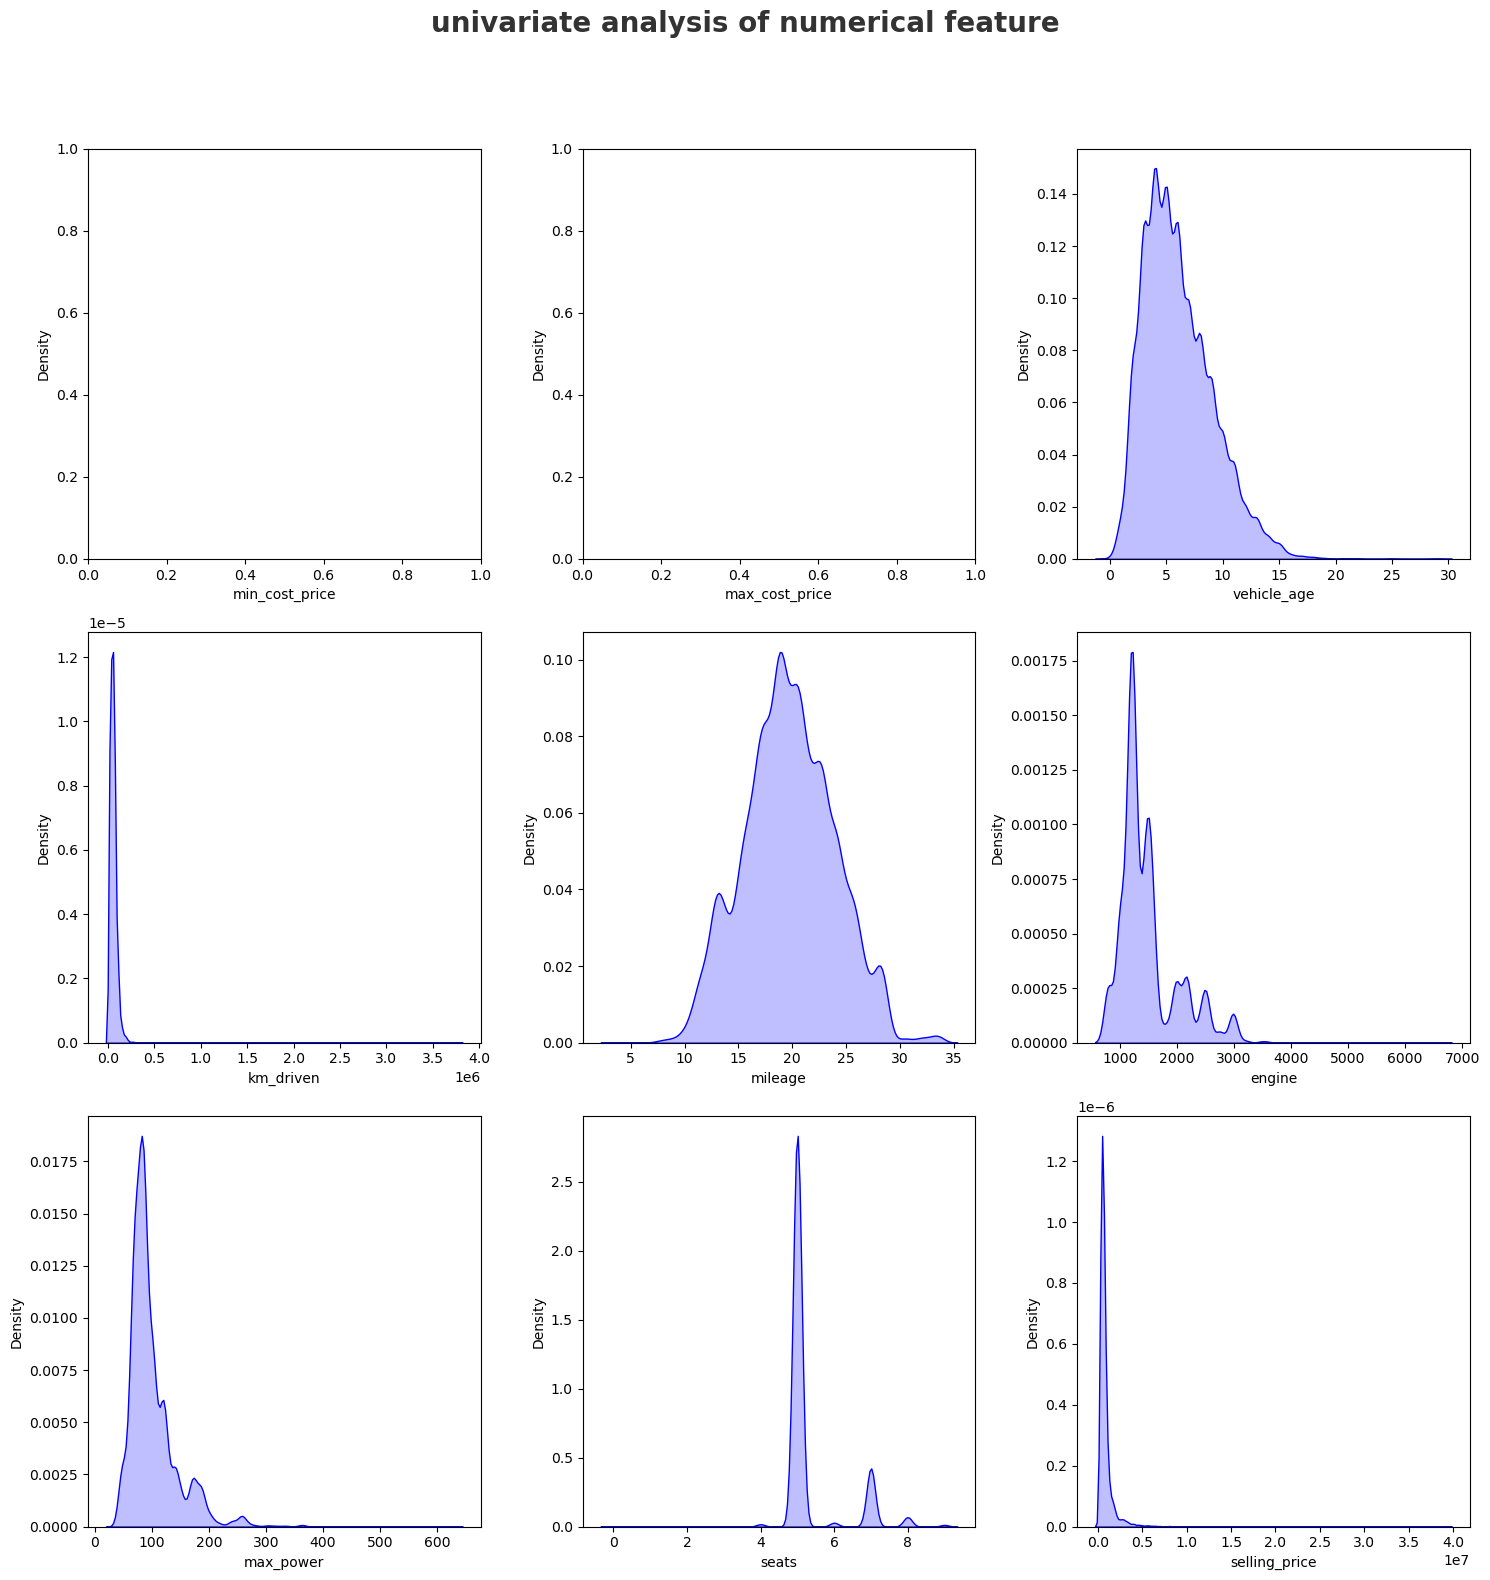

In [145]:
plt.figure(figsize=(15,15))
plt.suptitle('univariate analysis of numerical feature', fontsize=20, fontweight='bold', alpha=0.8, y=1.05)

for i in range(0,len(numeric_features)):
    plt.subplot(3,3, i+1)
    sns.kdeplot(x=df[numeric_features[i]],fill=True,color='b')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

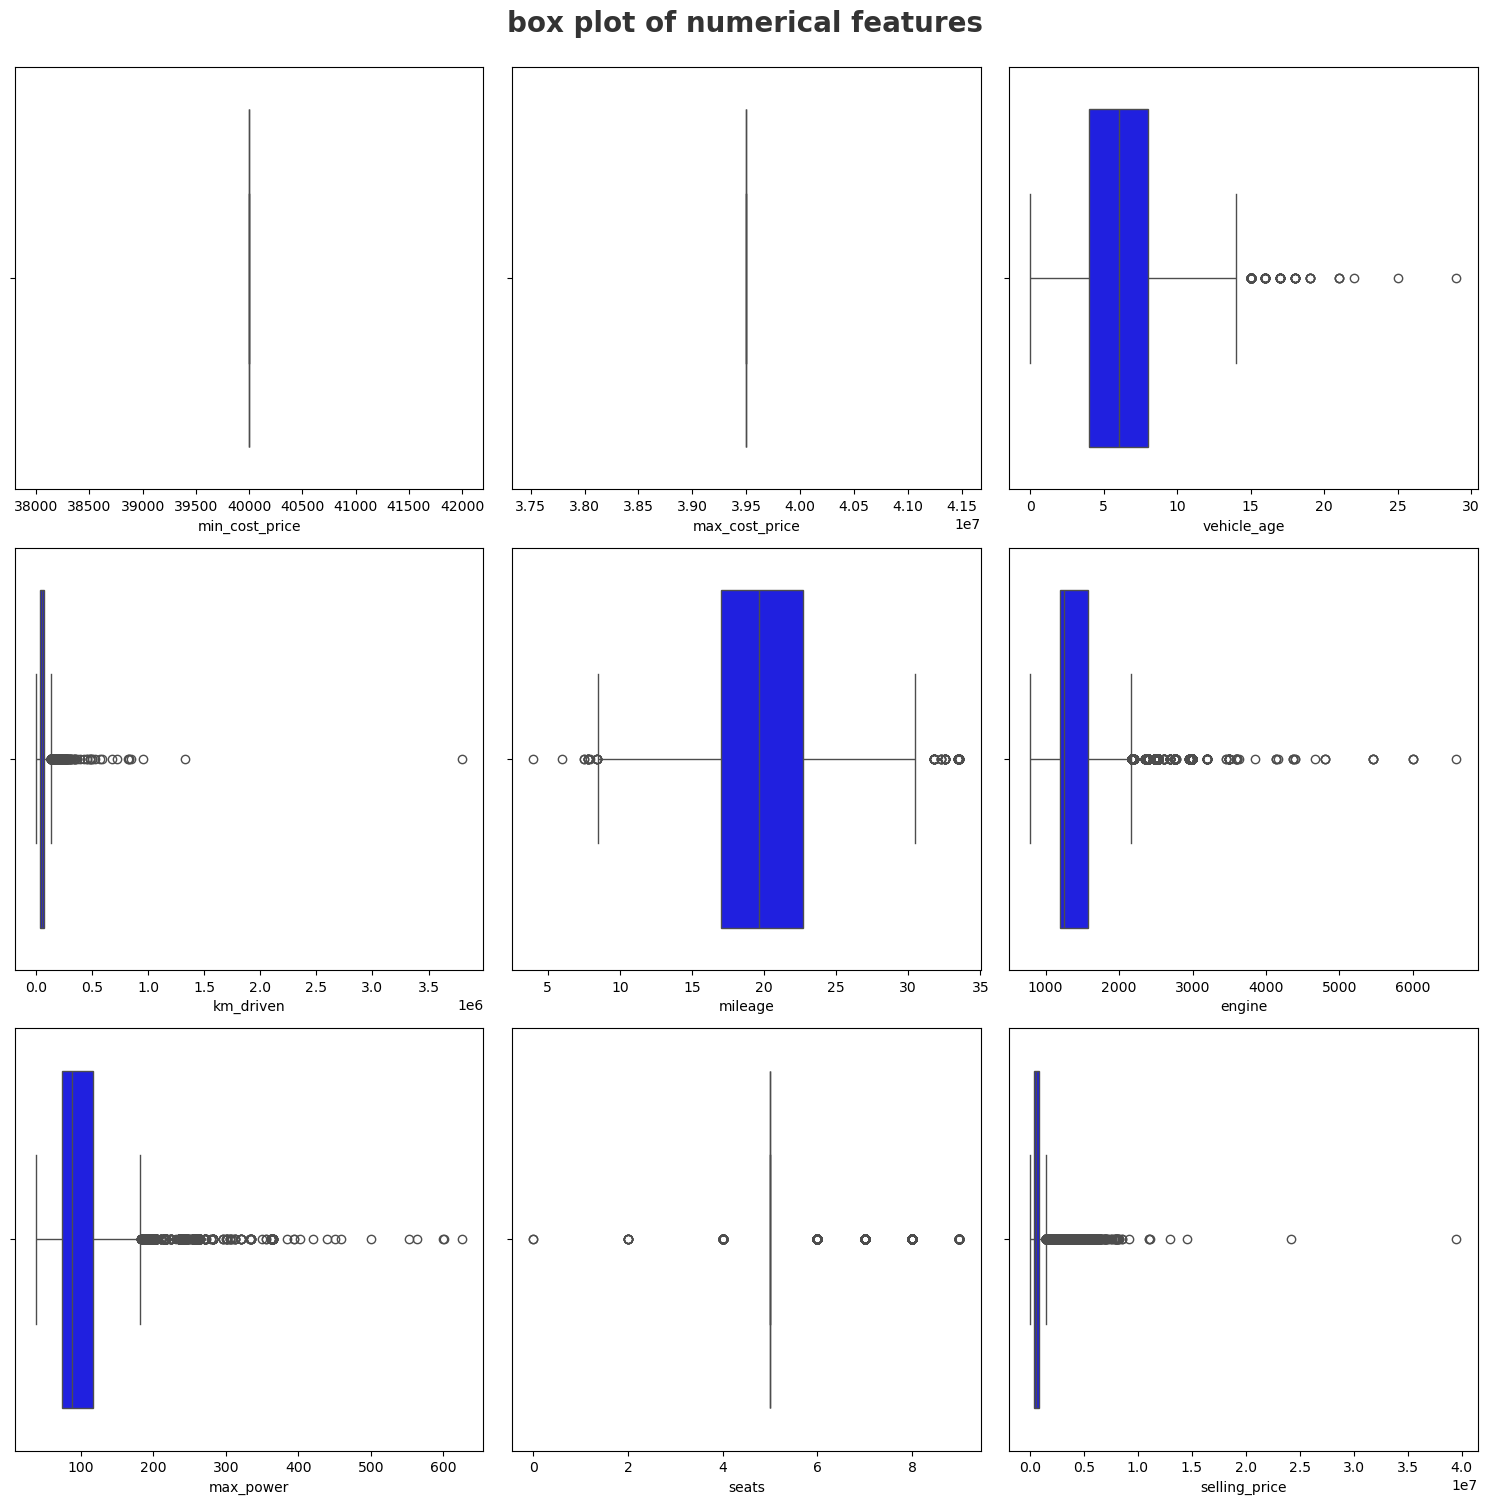

In [146]:
plt.figure(figsize=(15,15))
plt.suptitle('box plot of numerical features', fontsize=20, fontweight='bold', alpha=0.8, y=1.0)

for i in range(0,len(numeric_features)):
    plt.subplot(3,3, i+1)
    sns.boxplot(x=df[numeric_features[i]],fill=True,color='b')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

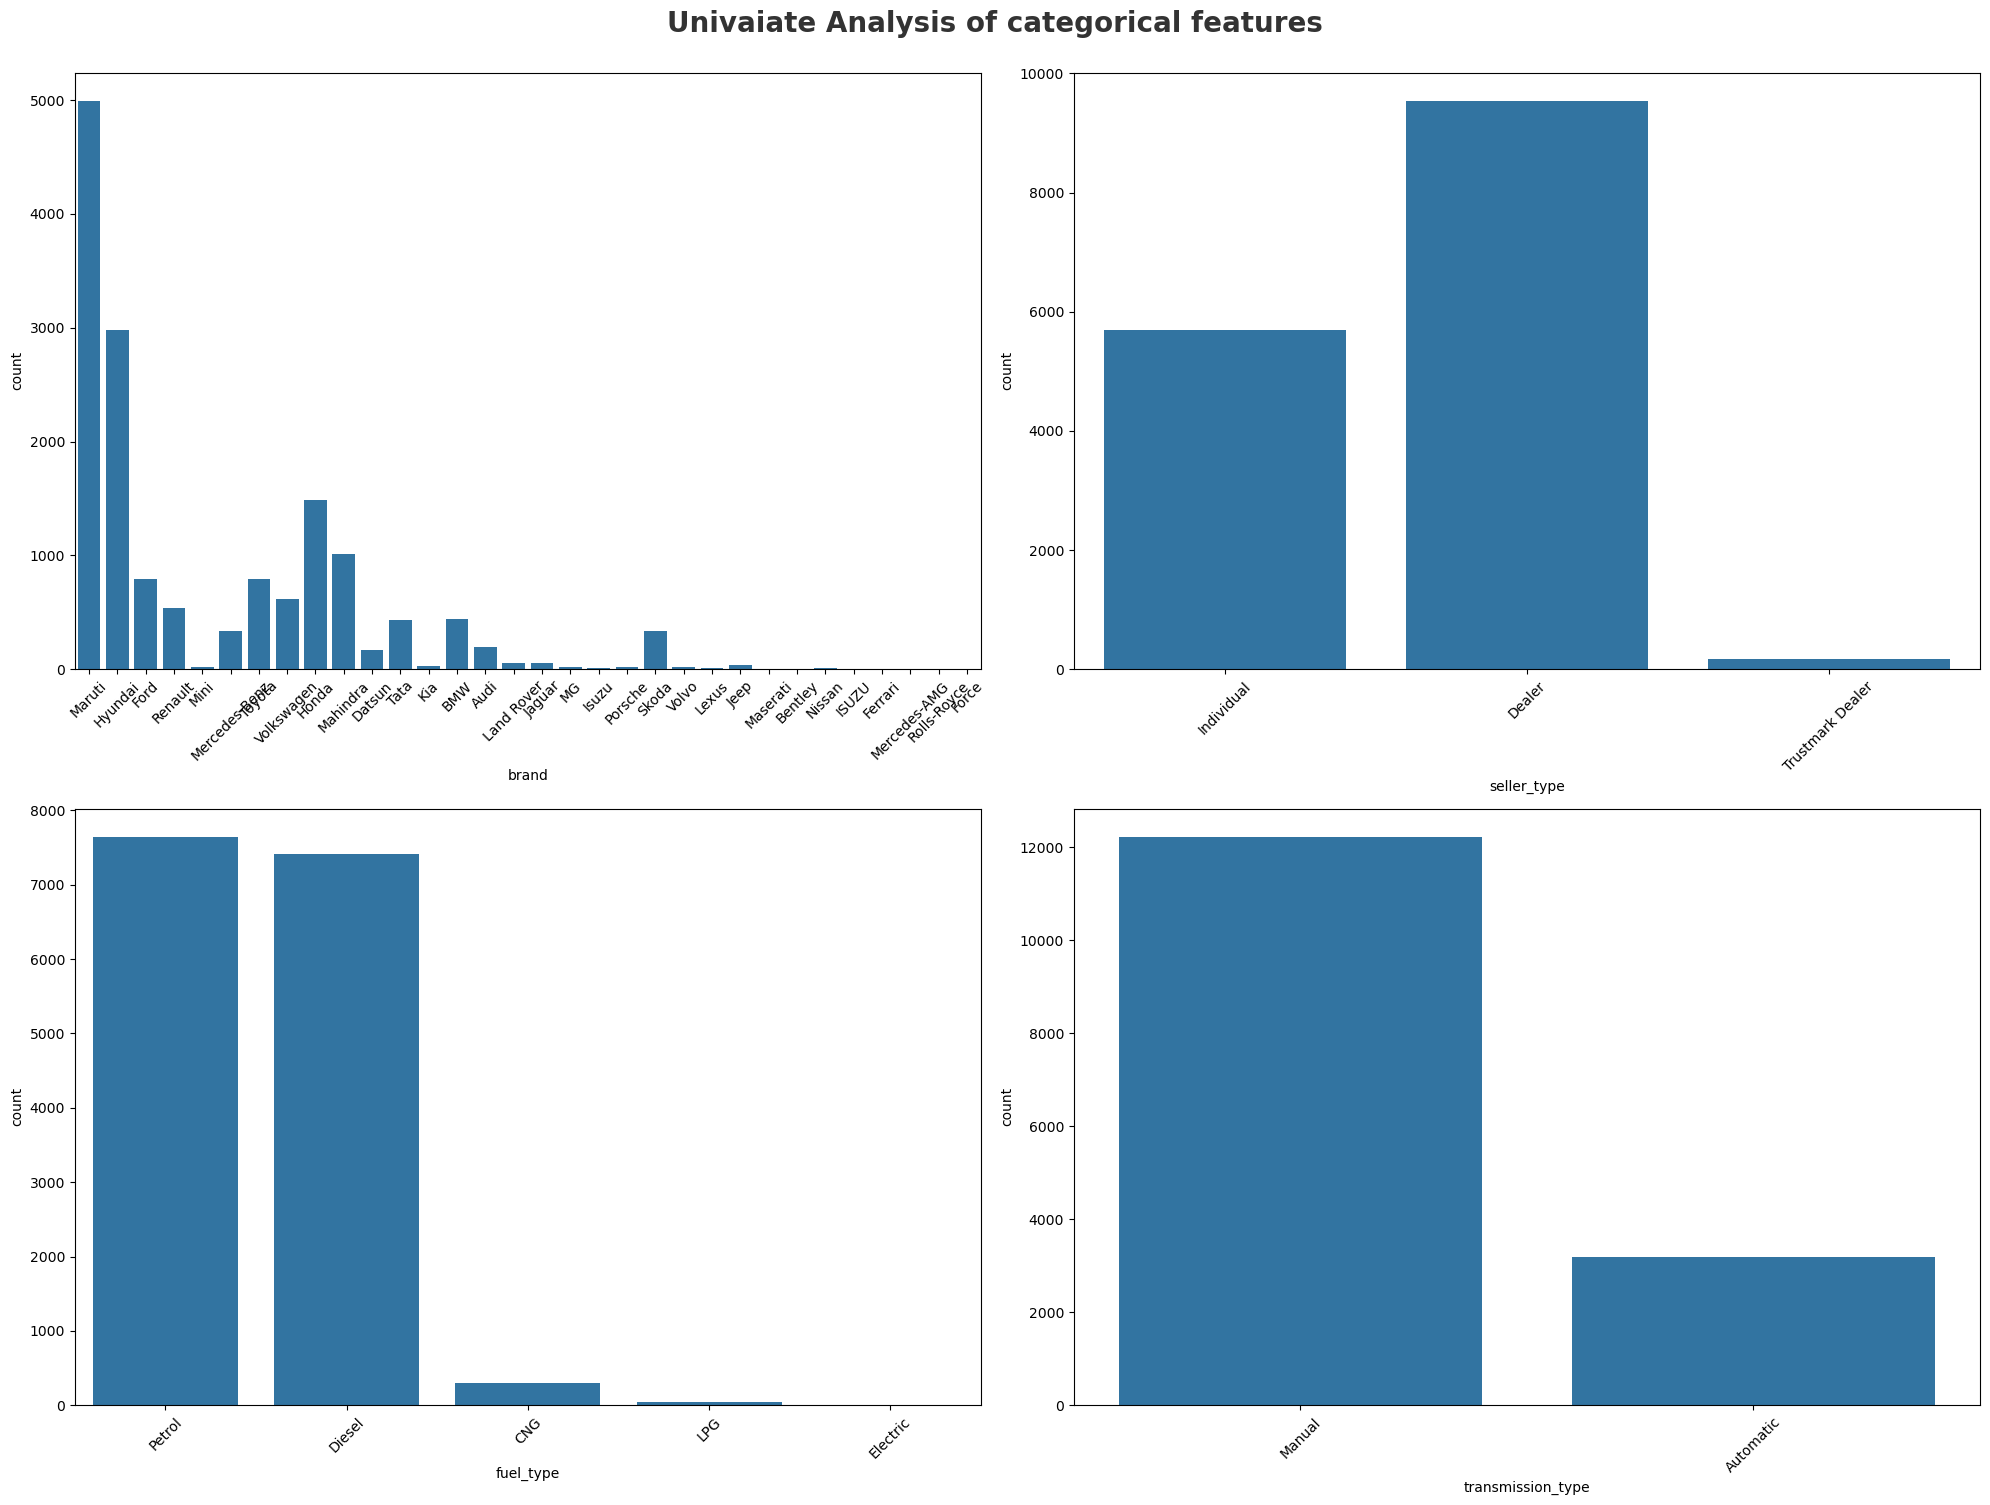

In [147]:
plt.figure(figsize=(20,15))
plt.suptitle("Univaiate Analysis of categorical features",fontsize=20, fontweight='bold',alpha=0.8, y=1.0)
             
cat1=['brand','seller_type','fuel_type','transmission_type']
for i in range(0,len(cat1)):
    plt.subplot(2,2,i+1)
    sns.countplot(x=df[cat1[i]])
    plt.xlabel(cat1[i])
    plt.xticks(rotation=45)
    plt.tight_layout()

## Bivariate Analysis

In [148]:
continuous_features=[feature for feature in numeric_features if len(df[feature].unique())>10]
print('Num of continuos features:', continuous_features)

Num of continuos features: ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price']


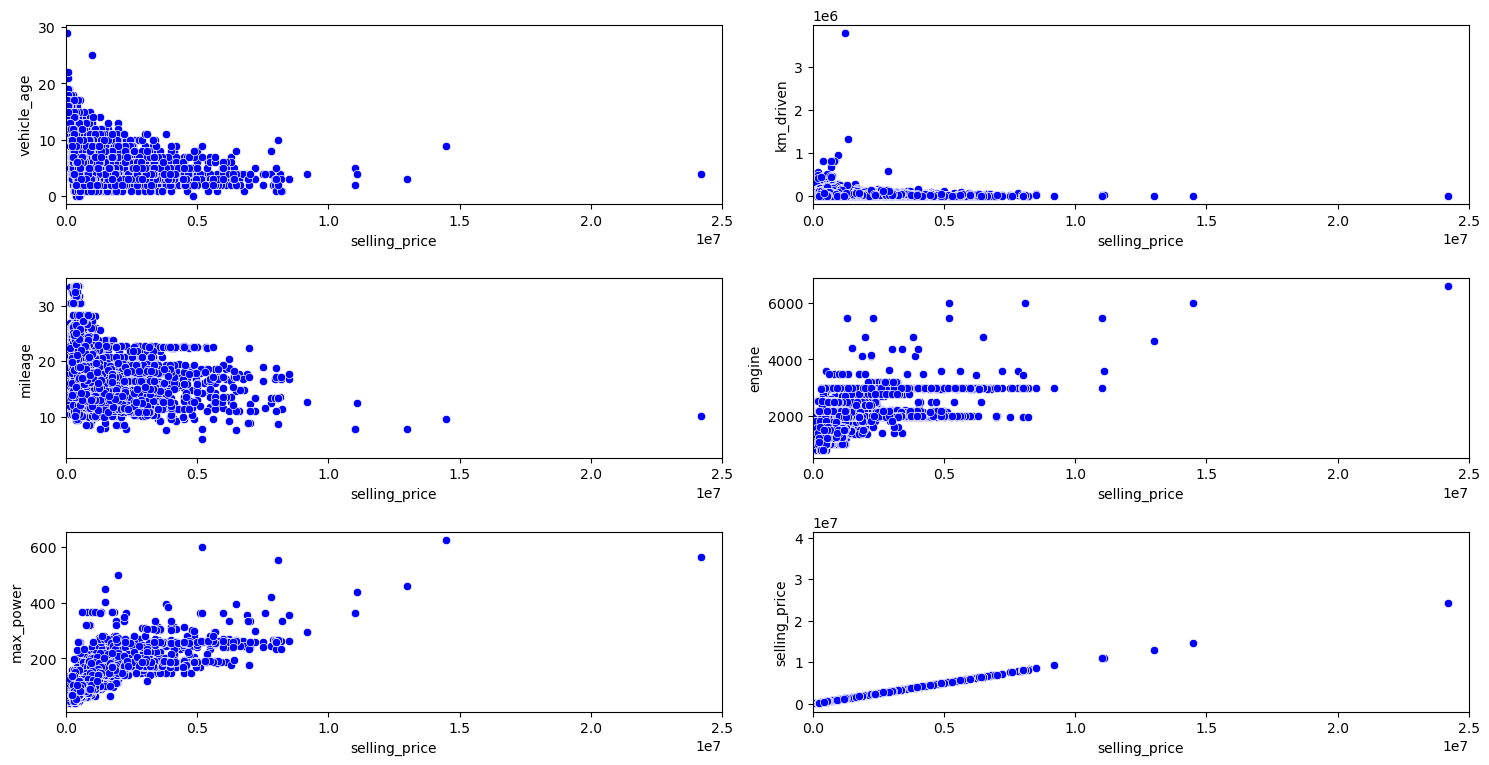

In [149]:
fig= plt.figure(figsize=(15,20))

for i in range(0, len(continuous_features)):
    ax=plt.subplot(8,2,i+1)

    sns.scatterplot(data=df, x='selling_price', y=continuous_features[i],color='b')
    plt.xlim(0,25000000) #limit to 25 lakh rupees 
    plt.tight_layout()

## Multivariate analysis

In [150]:
df[numeric_features].corr()

,min_cost_price,max_cost_price,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
min_cost_price,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_cost_price,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_age,NaN,NaN,1.000000,0.333891,-0.257394,0.098965,0.005208,0.030791,-0.241851
km_driven,NaN,NaN,0.333891,1.000000,-0.105239,0.192885,0.044421,0.192830,-0.080030
mileage,NaN,NaN,-0.257394,-0.105239,1.000000,-0.632987,-0.533128,-0.440280,-0.305549
engine,NaN,NaN,0.098965,0.192885,-0.632987,1.000000,0.807368,0.551236,0.585844
max_power,NaN,NaN,0.005208,0.044421,-0.533128,0.807368,1.000000,0.172257,0.750236
seats,NaN,NaN,0.030791,0.192830,-0.440280,0.551236,0.172257,1.000000,0.115033
selling_price,NaN,NaN,-0.241851,-0.080030,-0.305549,0.585844,0.750236,0.115033,1.000000


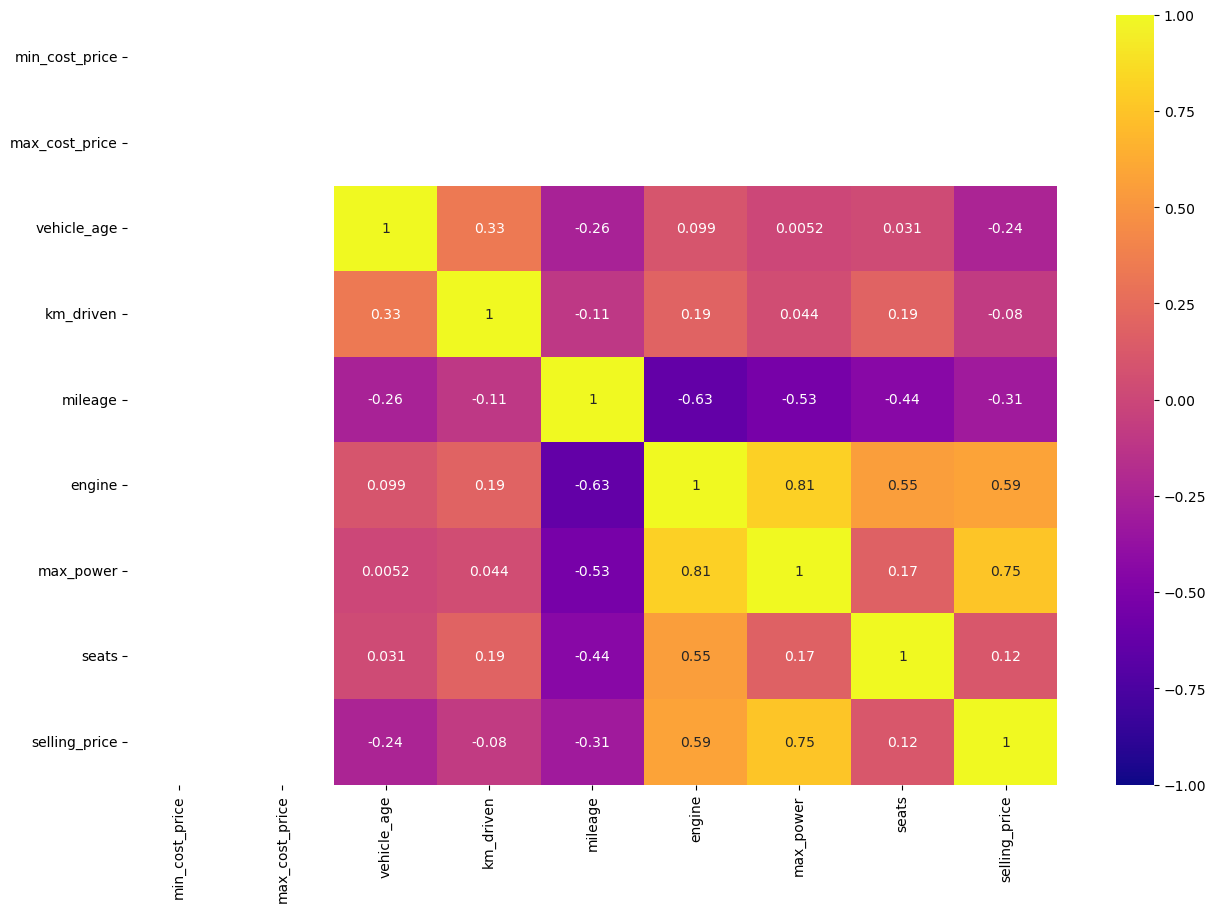

In [151]:
plt.figure(figsize=(15,10))
sns.heatmap(data=df[numeric_features].corr(),annot=True,cmap='plasma',vmin=-1,vmax=1,linecolor='white')
plt.show()

In [152]:
from scipy.stats import chi2_contingency

chi2_test = []

for feature in categorical_features:
    if chi2_contingency(pd.crosstab(df['selling_price'], df[feature]))[1] < 0.05:
        chi2_test.append('Reject Null Hypothesis')
    else:
        chi2_test.append('Fail to Reject Null Hypothesis')

test_result = pd.DataFrame({
    'Categorical Features': categorical_features,
    'Hypothesis Result': chi2_test
})

print('-' * 100)
print('Chi-squared test (checking multicollinearity for categorical features) results are as follows:')
print('-' * 100)
print(test_result)

----------------------------------------------------------------------------------------------------
Chi-squared test (checking multicollinearity for categorical features) results are as follows:
----------------------------------------------------------------------------------------------------
  Categorical Features       Hypothesis Result
0             car_name  Reject Null Hypothesis
1                brand  Reject Null Hypothesis
2                model  Reject Null Hypothesis
3          seller_type  Reject Null Hypothesis
4            fuel_type  Reject Null Hypothesis
5    transmission_type  Reject Null Hypothesis


## Selling price distribution(Target Feature Disturbution)

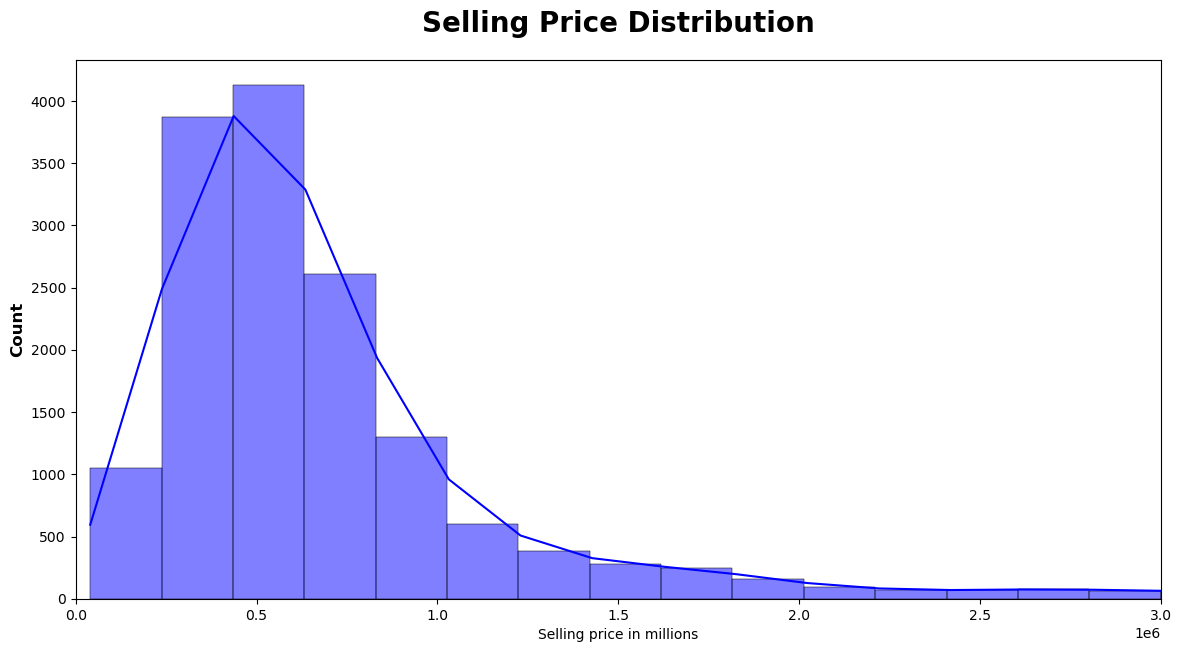

In [153]:
plt.subplots(figsize=(14,7))
sns.histplot(df.selling_price,bins=200,kde=True,color='b')
plt.title("Selling Price Distribution",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=12)
plt.xlabel("Selling price in millions")
plt.xlim(0,3000000)
plt.show()

In [154]:
print('-'*50)
print('Top 10 sold cars on Cardekho Website')
print('-'*50)
df.car_name.value_counts()[0:10]

--------------------------------------------------
Top 10 sold cars on Cardekho Website
--------------------------------------------------


car_name
Hyundai i20           906
Maruti Swift Dzire    890
Maruti Swift          781
Maruti Alto           778
Honda City            757
Maruti Wagon R        717
Hyundai Grand         580
Toyota Innova         545
Hyundai Verna         492
Hyundai i10           410
Name: count, dtype: int64

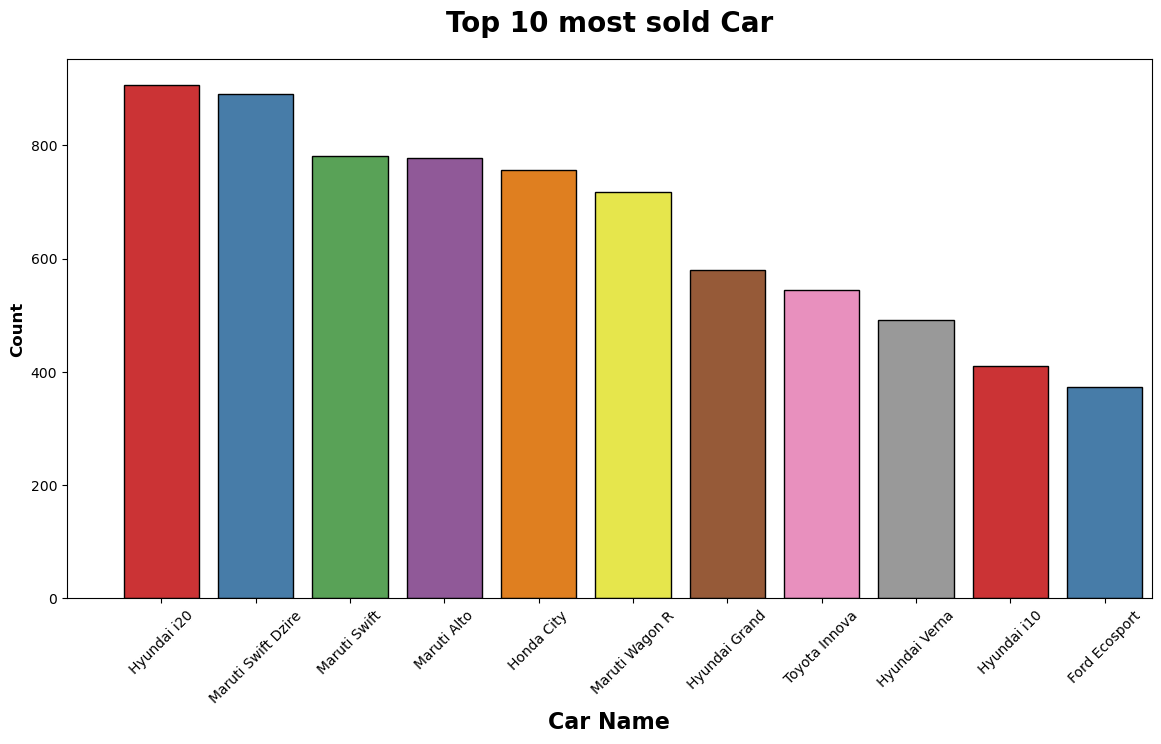

In [155]:
plt.subplots(figsize=(14,7))
sns.countplot(x='car_name',data=df,ec="black",palette="Set1",order=df['car_name'].value_counts().index)
plt.title("Top 10 most sold Car",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=12)
plt.xlabel("Car Name",weight="bold",fontsize=16)
plt.xticks(rotation=45)
plt.xlim(-1,10.5)
plt.show()

In [156]:
i20=df[df['car_name']=='Hyundai i20'] ['selling_price'].mean()
print(f'The mean price of Hyudnai i20 is {i20:2f} Rupees')

The mean price of Hyudnai i20 is 543603.752759 Rupees


## MOST sold car

In [157]:
print('-'*50)
print('Top 10 sold cars brand on Cardekho Website')
print('-'*50)
df.brand.value_counts()[0:10]

--------------------------------------------------
Top 10 sold cars brand on Cardekho Website
--------------------------------------------------


brand
Maruti        4992
Hyundai       2982
Honda         1485
Mahindra      1011
Toyota         793
Ford           790
Volkswagen     620
Renault        536
BMW            439
Tata           430
Name: count, dtype: int64

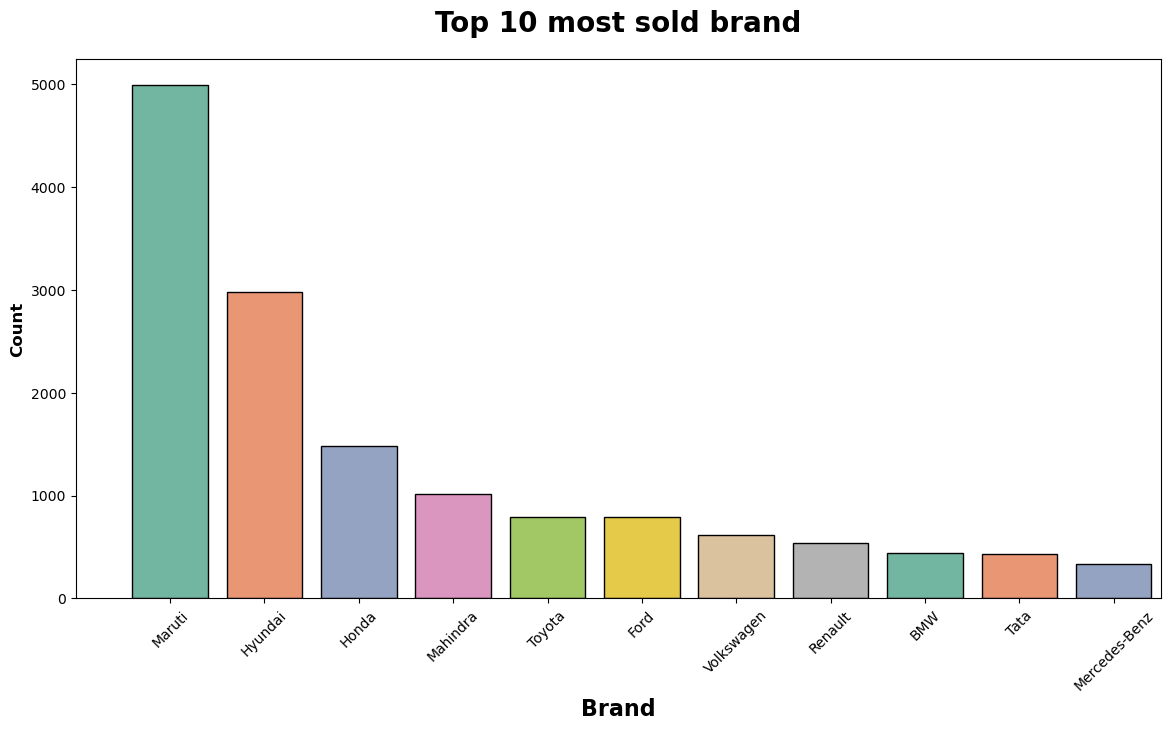

In [158]:
plt.subplots(figsize=(14,7))
sns.countplot(x='brand',data=df,ec="black",palette="Set2",order=df['brand'].value_counts().index)
plt.title("Top 10 most sold brand",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=12)
plt.xlabel("Brand",weight="bold",fontsize=16)
plt.xticks(rotation=45)
plt.xlim(-1,10.5)
plt.show()

In [159]:
Maruti=df[df['brand']=='Maruti'] ['selling_price'].mean()
print(f'The mean price of maruti is {Maruti:2f} Rupees')

The mean price of maruti is 487089.317909 Rupees


## Costlier Brand on Cardekho Website

In [160]:
brand=df.groupby('brand').selling_price.max()
brand=brand.to_frame().sort_values('selling_price',ascending=False)[0:10]

print('-'*50)
print('Top 10 costlier brands on cardekho Website')
print('-'*50)

brand

--------------------------------------------------
Top 10 costlier brands on cardekho Website
--------------------------------------------------


,selling_price
brand,
Ferrari,39500000
Rolls-Royce,24200000
Bentley,14500000
Mercedes-Benz,13000000
Porsche,11100000
Land Rover,9200000
BMW,8500000
Volvo,8195000
Lexus,8000000


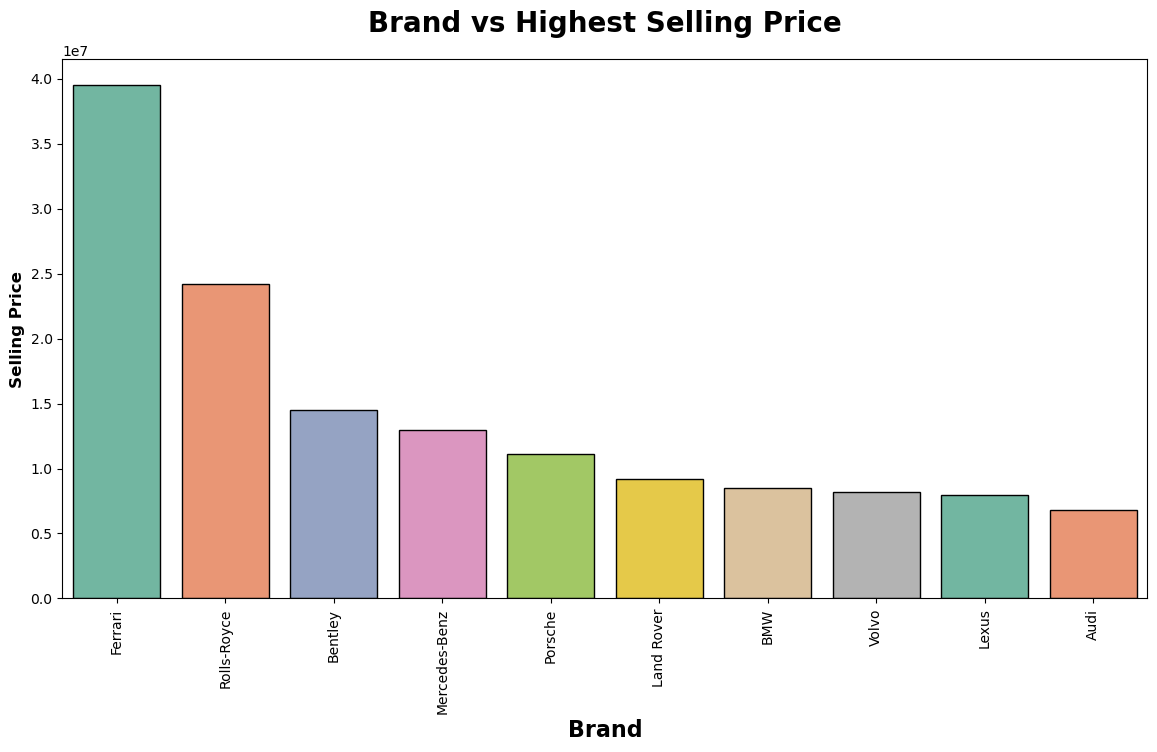

In [161]:
plt.subplots(figsize=(14,7))
sns.barplot(x=brand.index,y=brand.selling_price,ec="black",palette="Set2")
plt.title("Brand vs Highest Selling Price",weight="bold",fontsize=20,pad=20)
plt.ylabel("Selling Price",weight="bold",fontsize=12)
plt.xlabel("Brand",weight="bold",fontsize=16)
plt.xticks(rotation=90)
plt.show()

## Costlier Car on CarDekho website

In [162]:
car=df.groupby('car_name').selling_price.max()
car=car.to_frame().sort_values('selling_price',ascending=False)[0:10]

print('-'*50)
print('Top 10 costlier Cars on cardekho Website')
print('-'*50)

car

--------------------------------------------------
Top 10 costlier Cars on cardekho Website
--------------------------------------------------


,selling_price
car_name,
Ferrari GTC4Lusso,39500000
Rolls-Royce Ghost,24200000
Bentley Continental,14500000
Mercedes-Benz S-Class,13000000
Porsche Cayenne,11100000
Land Rover Rover,9200000
BMW 7,8500000
BMW Z4,8250000
Volvo XC,8195000


## Most mileage Car Brand on Cardekho Website

In [163]:
mileage=df.groupby('brand')['mileage'].mean().sort_values(ascending=False).head(15)

print('-'*50)
print('Top 10 costlier Cars on cardekho Website')
print('-'*50)

mileage.to_frame()

--------------------------------------------------
Top 10 costlier Cars on cardekho Website
--------------------------------------------------


,mileage
brand,
Maruti,22.430980
Renault,22.099142
Datsun,21.215647
Lexus,20.846000
Ford,19.922620
Honda,19.908795
Maserati,19.820000
Tata,19.755279
Hyundai,19.588776


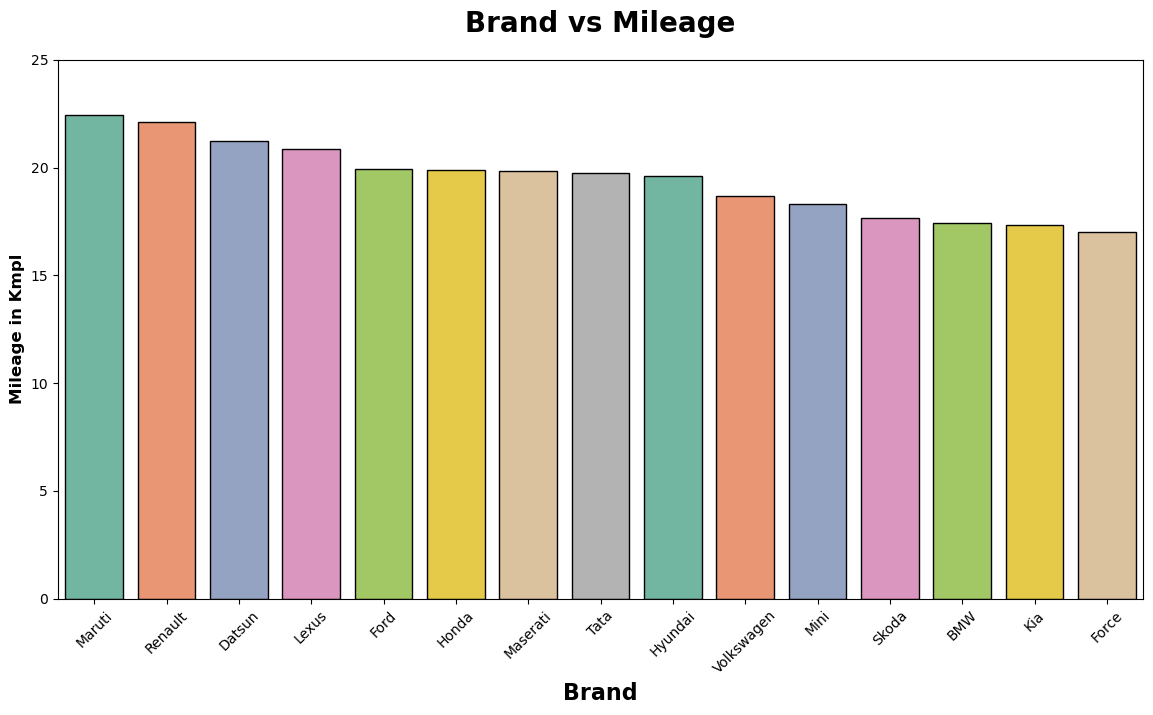

In [164]:
plt.subplots(figsize=(14,7))
sns.barplot(x=mileage.index,y=mileage.values,ec="black",palette="Set2")
plt.title("Brand vs Mileage",weight="bold",fontsize=20,pad=20)
plt.ylabel("Mileage in Kmpl",weight="bold",fontsize=12)
plt.xlabel("Brand",weight="bold",fontsize=16)
plt.ylim(0,25)
plt.xticks(rotation=45)
plt.show()

## Most Mileage Car on Cardekho


In [165]:
mileage_car=df.groupby('car_name')['mileage'].mean().sort_values(ascending=False).head(15)

print('-'*50)
print('Top 10 costlier Cars on cardekho Website')
print('-'*50)

mileage_car.to_frame()

--------------------------------------------------
Top 10 costlier Cars on cardekho Website
--------------------------------------------------


,mileage
car_name,
Tata Tiago,24.625103
Maruti Ciaz,24.289046
Maruti Vitara,24.231932
Renault KWID,24.037810
Maruti Celerio,23.703502
Maruti Dzire VXI,23.512941
Maruti Dzire LXI,23.260000
Maruti Dzire ZXI,23.260000
Ford Aspire,22.993846


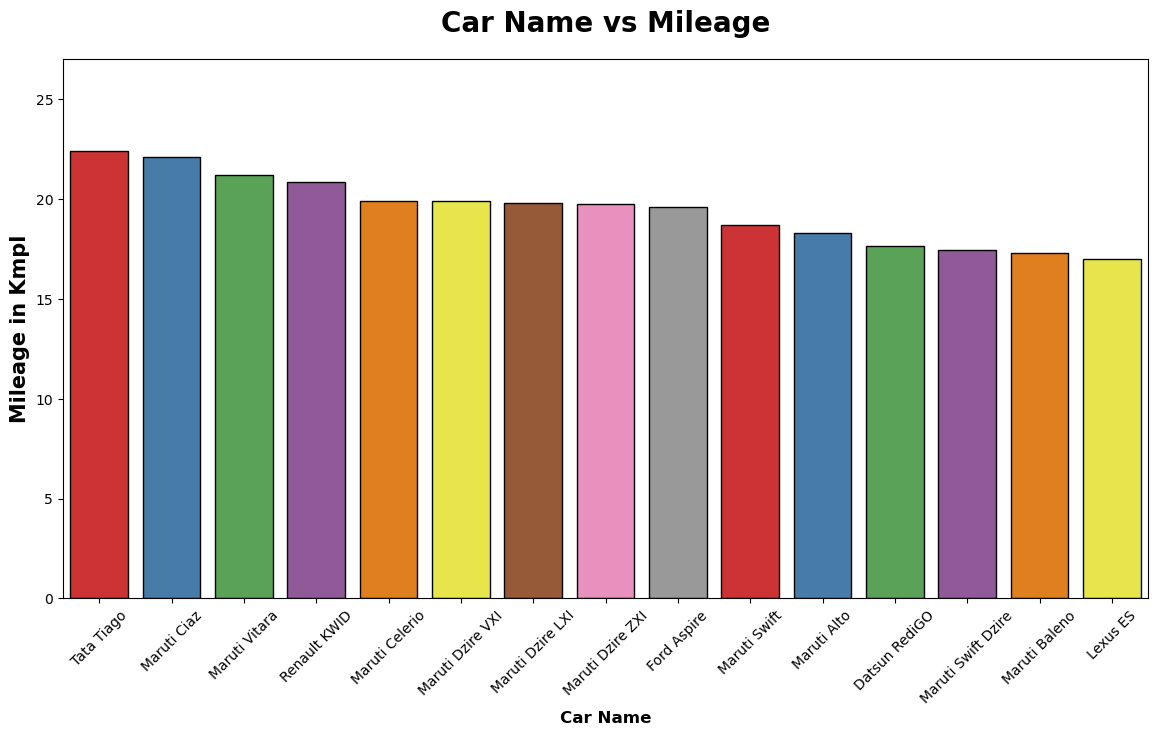

In [166]:
plt.subplots(figsize=(14,7))
sns.barplot(x=mileage_car.index,y=mileage.values,ec="black",palette="Set1")
plt.title("Car Name vs Mileage",weight="bold",fontsize=20,pad=20)
plt.ylabel("Mileage in Kmpl",weight="bold",fontsize=15)
plt.xlabel("Car Name",weight="bold",fontsize=12)
plt.ylim(0,27)
plt.xticks(rotation=45)
plt.show()

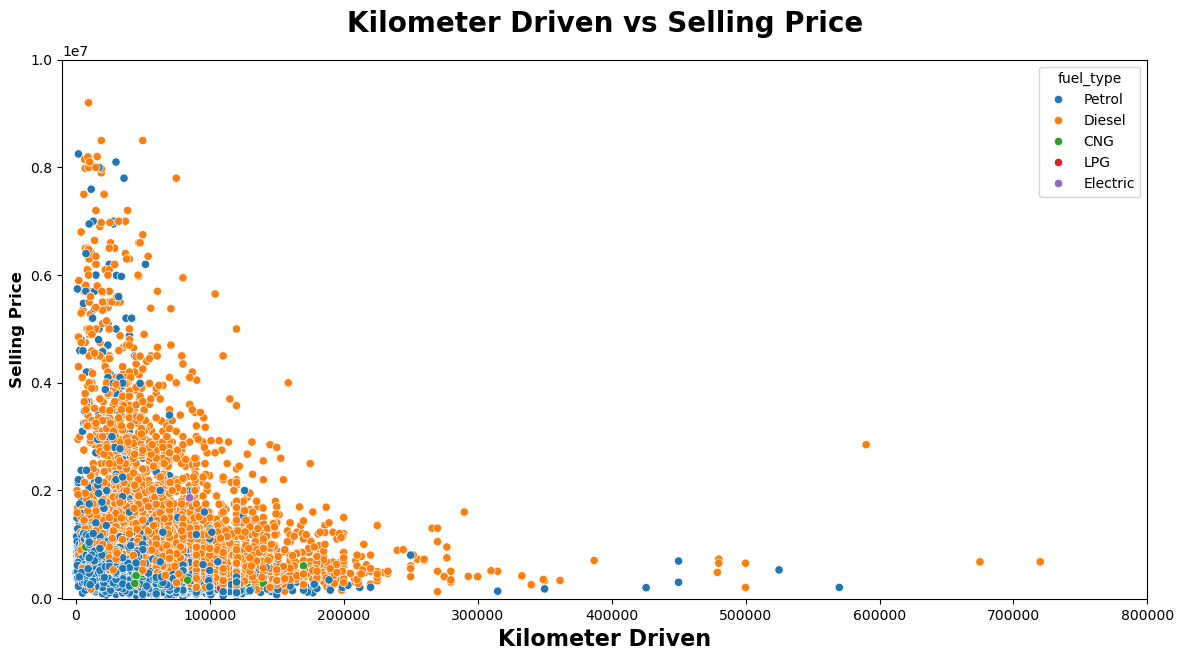

In [167]:
plt.subplots(figsize=(14,7))
sns.scatterplot(x="km_driven",y="selling_price",data=df,ec="white",color='b',hue='fuel_type')
plt.title("Kilometer Driven vs Selling Price",weight="bold",fontsize=20,pad=20)
plt.ylabel("Selling Price",weight="bold",fontsize=12)
plt.xlim(-10000,800000)
plt.ylim(-10000,10000000)
plt.xlabel("Kilometer Driven",weight="bold",fontsize=16)
plt.show()

In [168]:
fuel=df.groupby('fuel_type')['selling_price'].median().sort_values(ascending=False)
fuel.to_frame()

,selling_price
fuel_type,
Electric,1857500.0
Diesel,700000.0
Petrol,460000.0
CNG,370000.0
LPG,182500.0


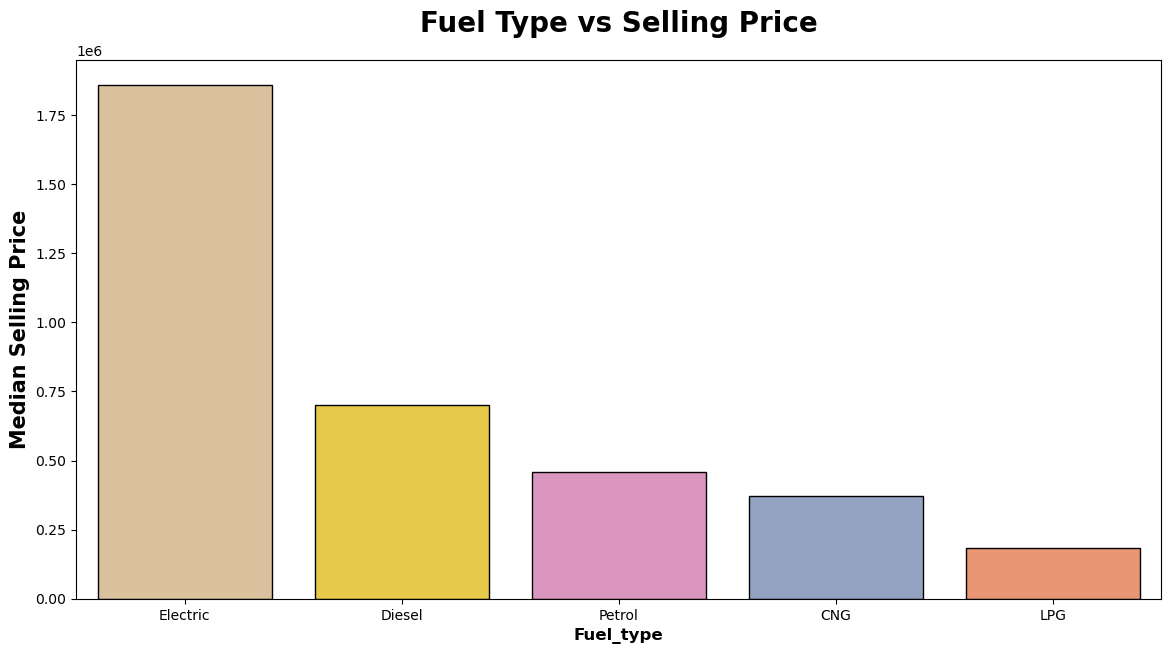

In [169]:
plt.subplots(figsize=(14,7))
sns.barplot(x=fuel.index,y=fuel.values,ec="black",palette="Set2_r")
plt.title("Fuel Type vs Selling Price",weight="bold",fontsize=20,pad=20)
plt.ylabel("Median Selling Price",weight="bold",fontsize=15)
plt.xlabel("Fuel_type",weight="bold",fontsize=12)
plt.show()

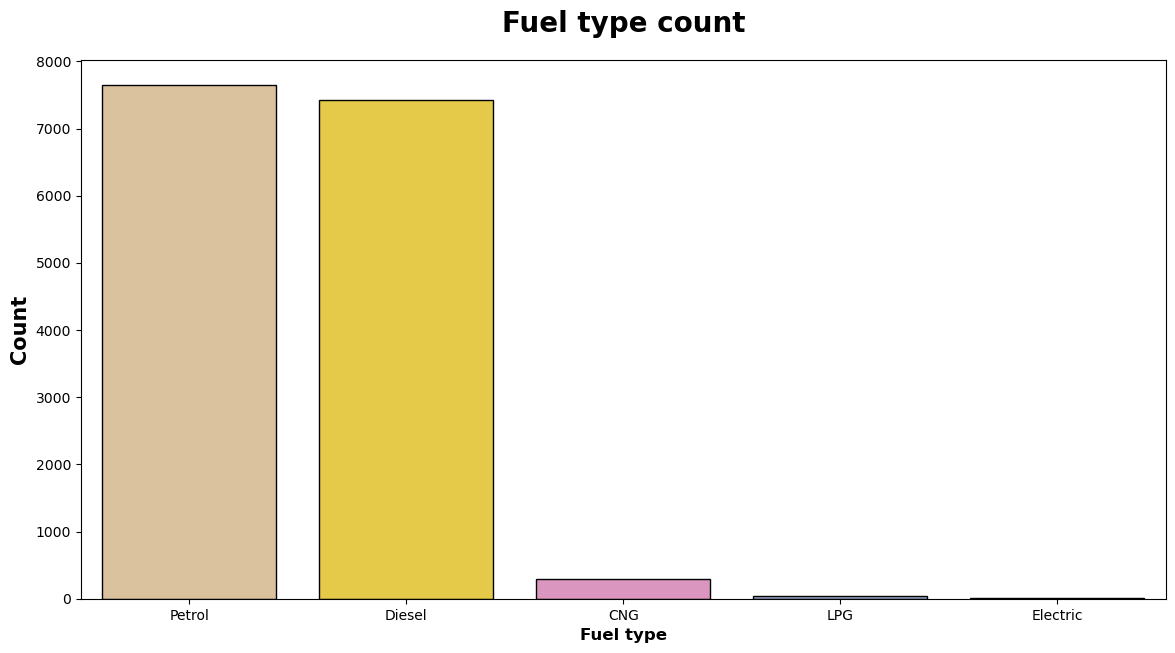

In [170]:
plt.subplots(figsize=(14,7))
sns.countplot(x=df.fuel_type,ec="black",palette="Set2_r")
plt.title("Fuel type count",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=15)
plt.xlabel("Fuel type",weight="bold",fontsize=12)
plt.show()

## Fuel Type Vs Mileage

In [171]:
fuel_mileage=df.groupby('fuel_type')['mileage'].mean().sort_values(ascending=False)
fuel_mileage.to_frame()

,mileage
fuel_type,
CNG,25.814651
Diesel,20.060030
Electric,19.160000
Petrol,19.123045
LPG,17.836364


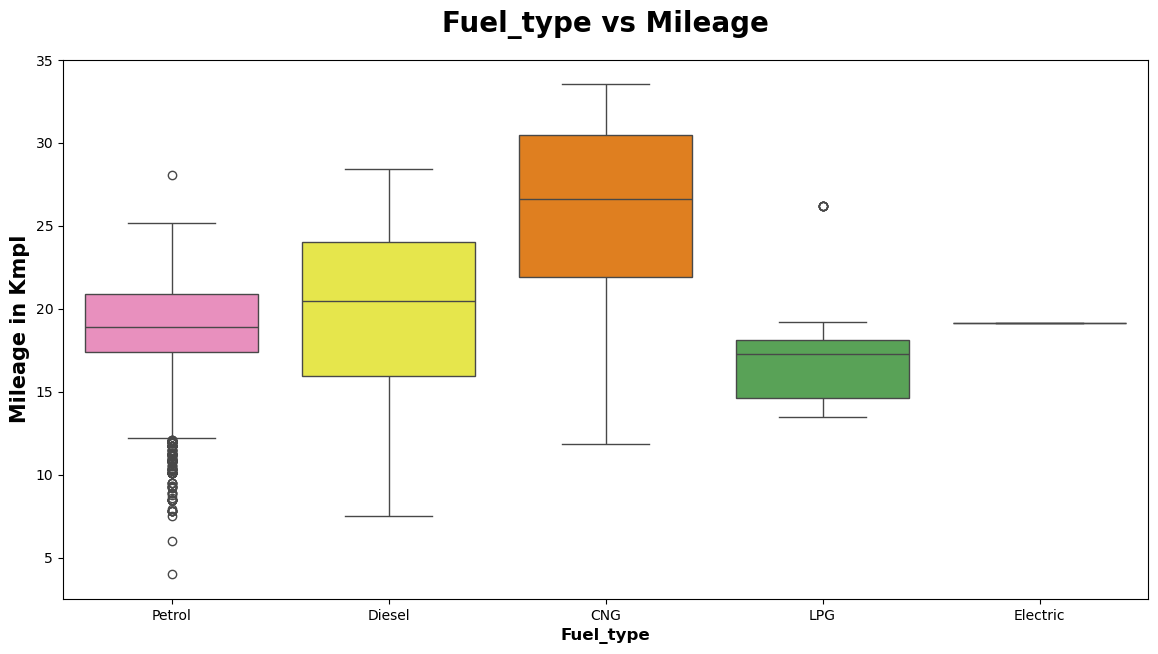

In [172]:
plt.subplots(figsize=(14,7))
sns.boxplot(x='fuel_type',y='mileage',data=df,palette="Set1_r")
plt.title("Fuel_type vs Mileage",weight="bold",fontsize=20,pad=20)
plt.ylabel("Mileage in Kmpl",weight="bold",fontsize=15)
plt.xlabel("Fuel_type",weight="bold",fontsize=12)
plt.show()

# Mileage vs Selling Price

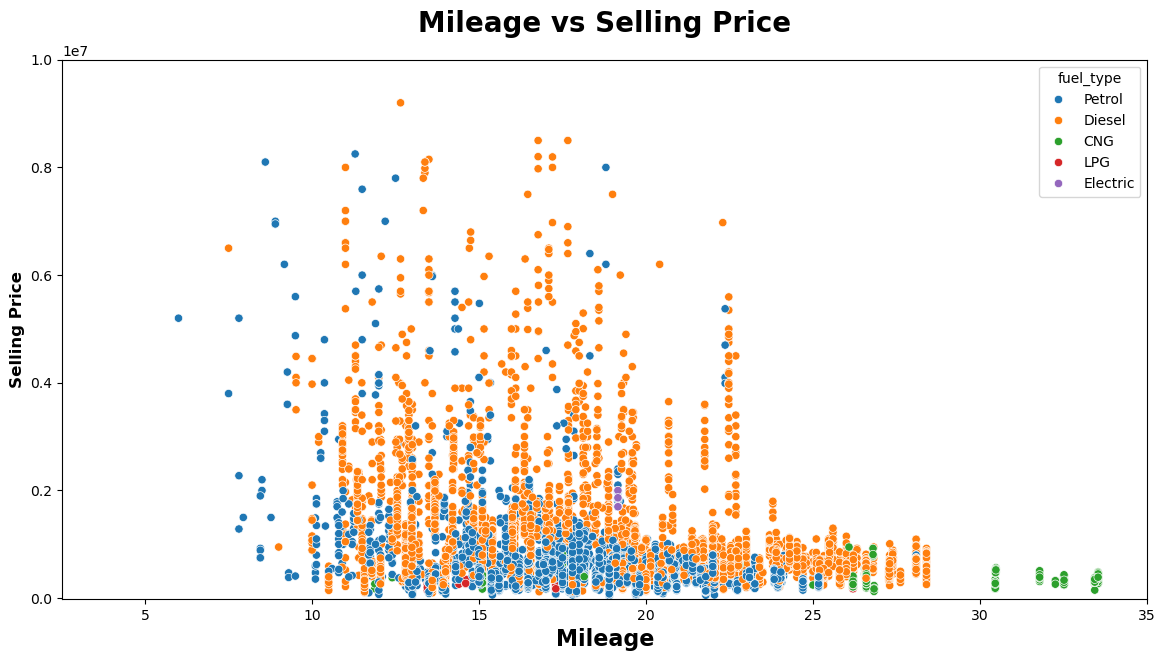

In [173]:
plt.subplots(figsize=(14,7))
sns.scatterplot(x="mileage",y="selling_price",data=df,ec="white",color='b',hue='fuel_type')
plt.title("Mileage vs Selling Price",weight="bold",fontsize=20,pad=20)
plt.ylabel("Selling Price",weight="bold",fontsize=12)
plt.ylim(-10000,10000000)
plt.xlabel("Mileage",weight="bold",fontsize=16)
plt.show()

# Mileage Distribution

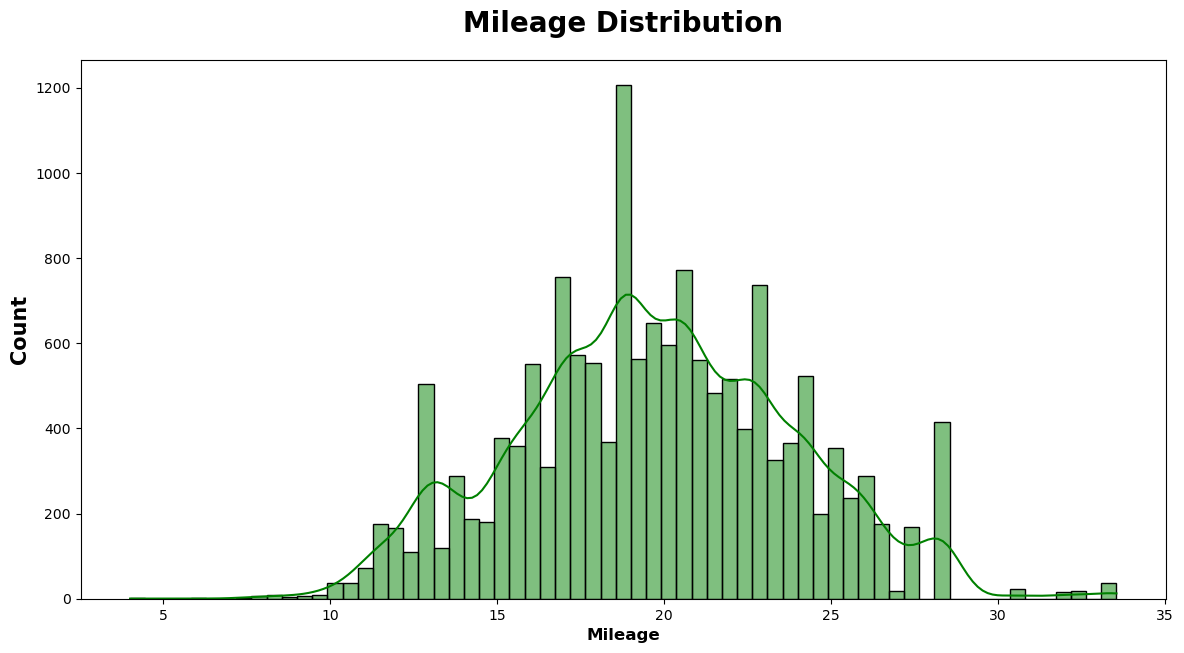

In [174]:
plt.subplots(figsize=(14,7))
sns.histplot(x=df.mileage,ec="black",color='g',kde=True)
plt.title("Mileage Distribution",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=15)
plt.xlabel("Mileage",weight="bold",fontsize=12)
plt.show()

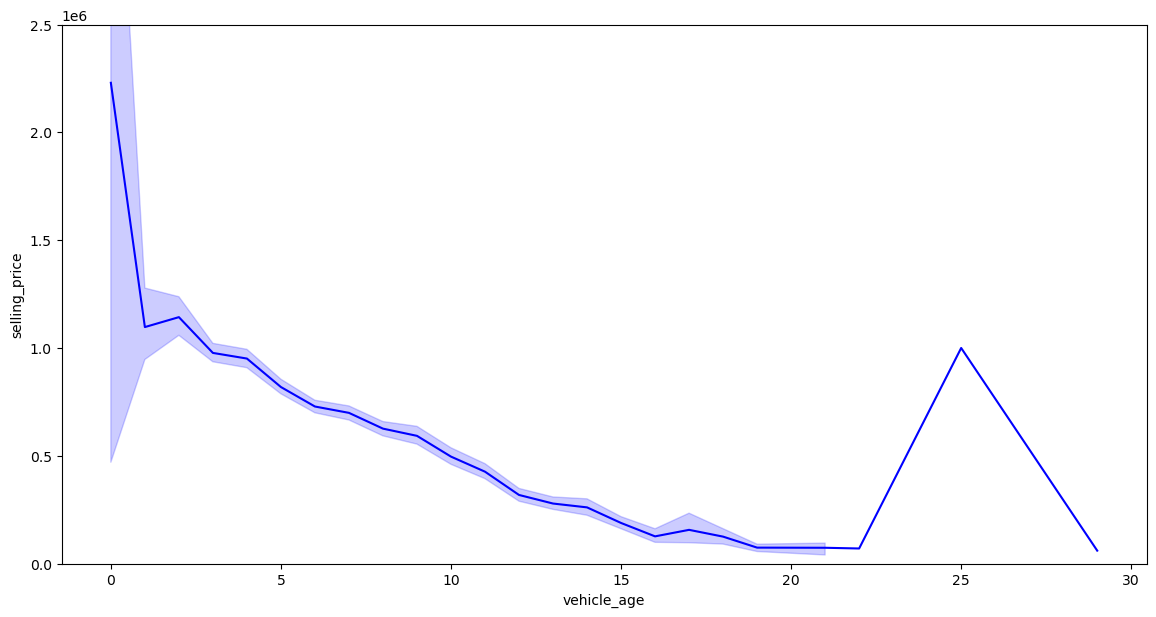

In [175]:
plt.subplots(figsize=(14,7))
sns .lineplot(x="vehicle_age",y="selling_price",data=df,color='b')
plt.ylim(0,2500000)
plt.show()

# vehicle Age VS Mileage

In [176]:
vehicle_age=df.groupby('vehicle_age')['mileage'].median().sort_values(ascending=False)
vehicle_age.to_frame(5)

,5
vehicle_age,
29,22.05
0,21.70
3,21.21
4,20.63
5,20.51
6,20.14
7,20.00
1,20.00
2,19.60


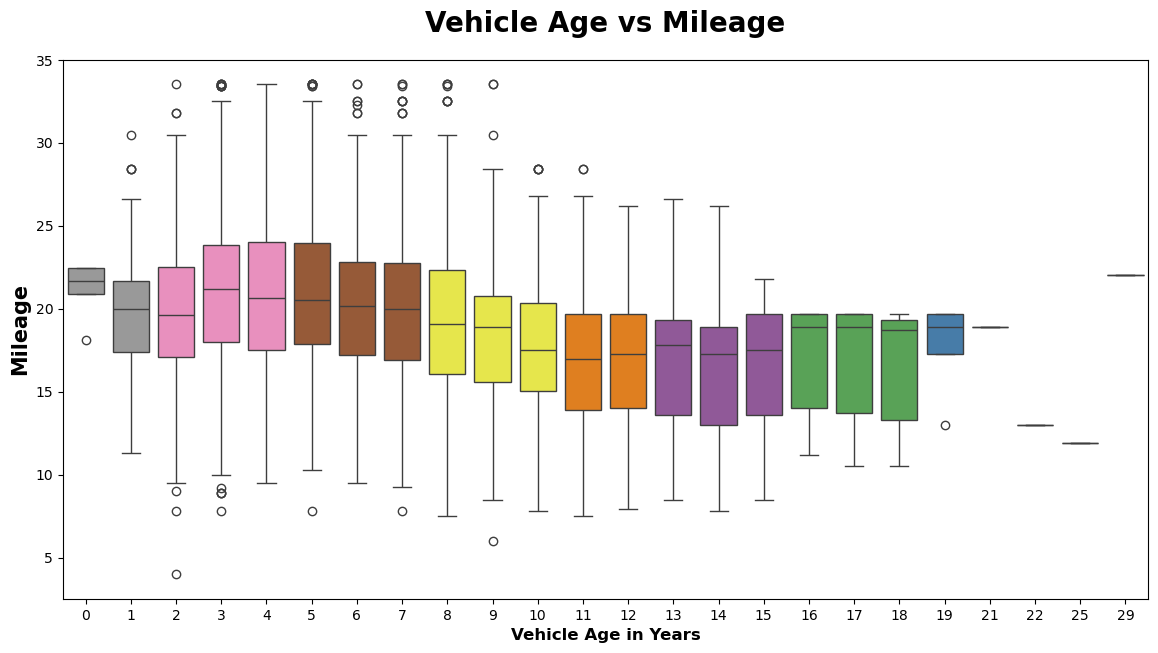

In [177]:
plt.subplots(figsize=(14,7))
sns.boxplot(x=df.vehicle_age,y=df.mileage,data=df,palette="Set1_r")
plt.title("Vehicle Age vs Mileage",weight="bold",fontsize=20,pad=20)
plt.ylabel("Mileage",weight="bold",fontsize=15)
plt.xlabel("Vehicle Age in Years",weight="bold",fontsize=12)
plt.show()

In [178]:
oldest=df.groupby('car_name')['vehicle_age'].max().sort_values(ascending=False).head(10)
oldest.to_frame()

,vehicle_age
car_name,
Maruti Alto,29
BMW 3,25
Honda City,22
Maruti Wagon R,21
Mahindra Bolero,18
Mahindra Scorpio,18
Skoda Octavia,18
Honda CR-V,17
Mercedes-Benz E-Class,17


# Transmission

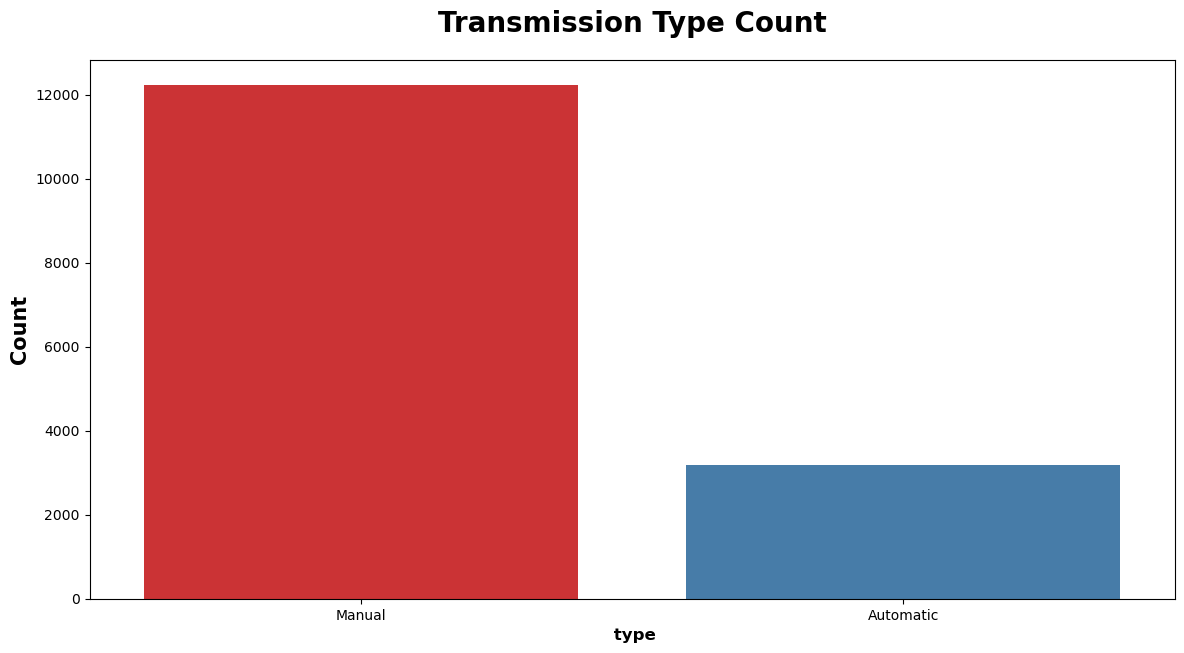

In [179]:
plt.subplots(figsize=(14,7))
sns.countplot(x='transmission_type',data=df,palette="Set1")
plt.title("Transmission Type Count",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=15)
plt.xlabel(" type",weight="bold",fontsize=12)
plt.show()

# Transmission Type Vs Selling Price

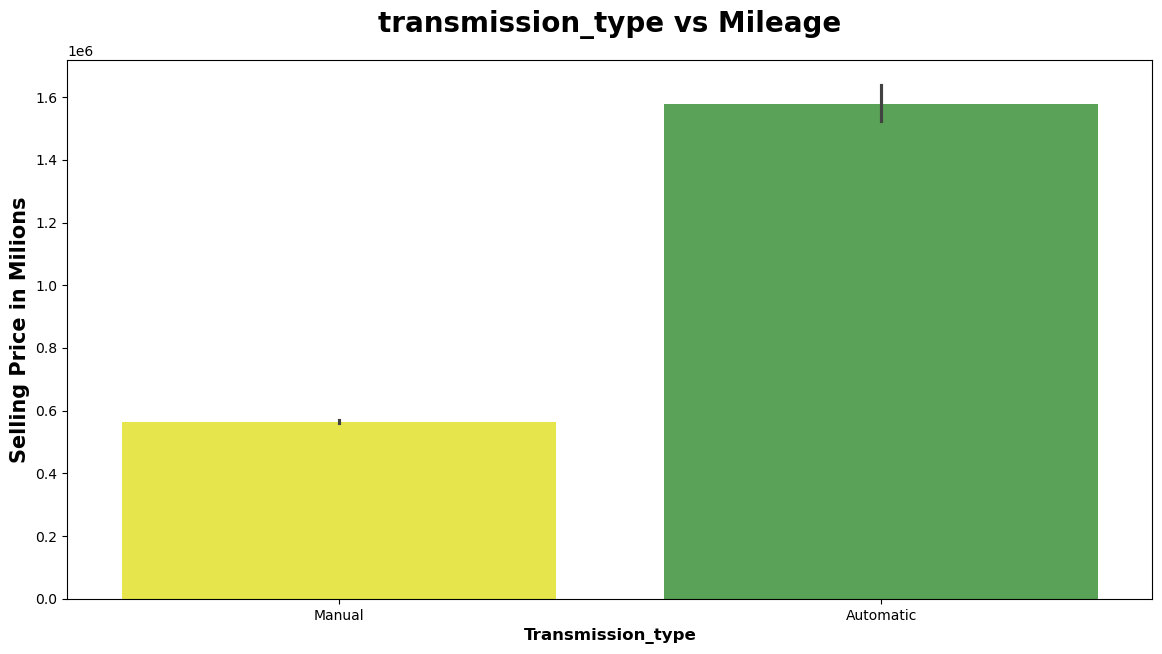

In [180]:
plt.subplots(figsize=(14,7))
sns.barplot(x='transmission_type',y='selling_price',data=df,palette="Set1_r")
plt.title("transmission_type vs Mileage",weight="bold",fontsize=20,pad=20)
plt.ylabel("Selling Price in Milions",weight="bold",fontsize=15)
plt.xlabel("Transmission_type",weight="bold",fontsize=12)
plt.show()

# Seller Type Vs Count

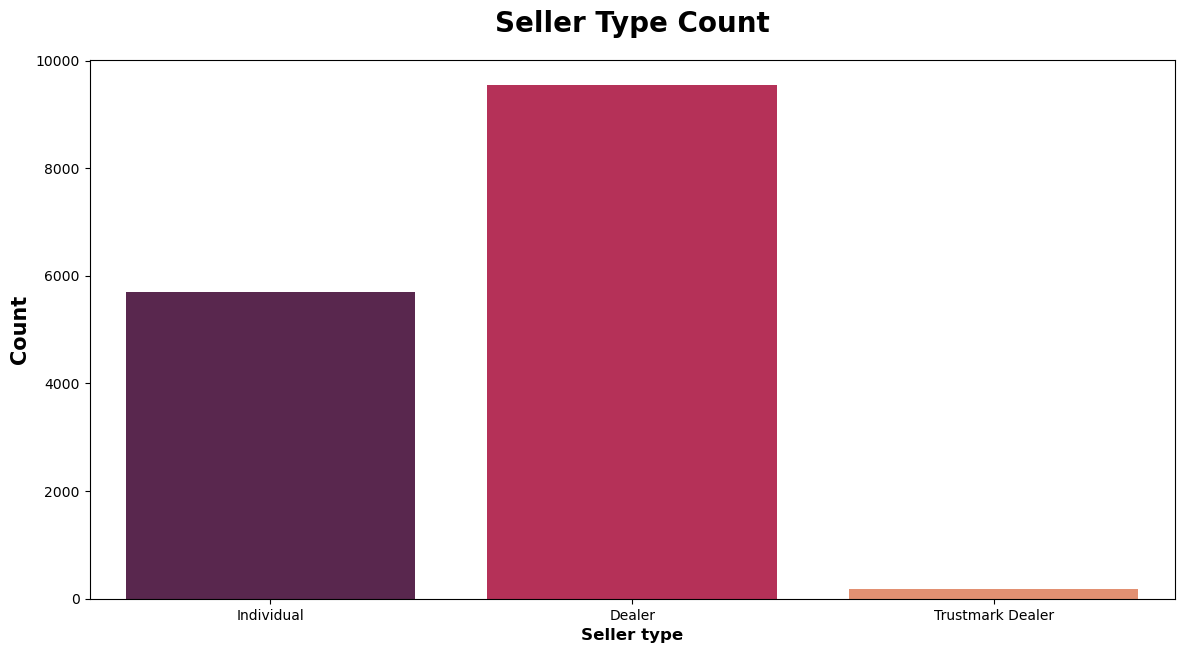

In [181]:
plt.subplots(figsize=(14,7))
sns.countplot(x='seller_type',data=df,palette="rocket")
plt.title("Seller Type Count",weight="bold",fontsize=20,pad=20)
plt.ylabel("Count",weight="bold",fontsize=15)
plt.xlabel("Seller type",weight="bold",fontsize=12)
plt.show()

In [182]:
dealer=df.groupby('seller_type')['selling_price'].max().sort_values(ascending=False)
dealer.to_frame()

,selling_price
seller_type,
Dealer,39500000
Individual,24200000
Trustmark Dealer,1575000


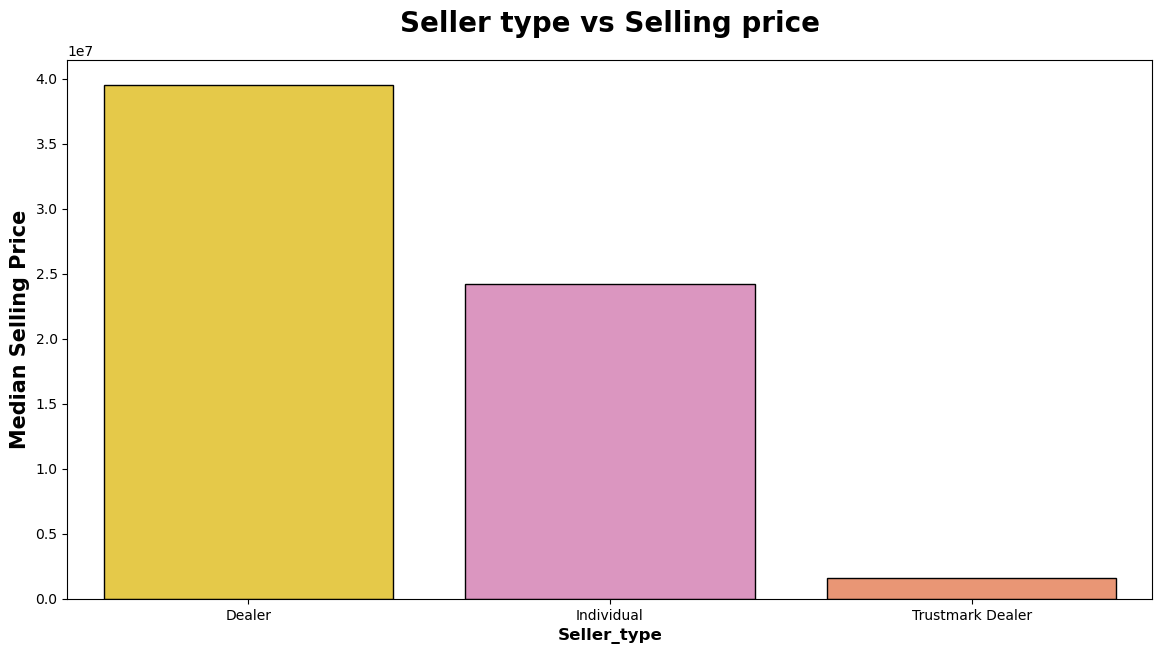

In [183]:
plt.subplots(figsize=(14,7))
sns.barplot(x=dealer.index,y=dealer.values,ec='black',palette="Set2_r")
plt.title("Seller type vs Selling price",weight="bold",fontsize=20,pad=20)
plt.ylabel("Median Selling Price",weight="bold",fontsize=15)
plt.xlabel("Seller_type",weight="bold",fontsize=12)
plt.show()


# 9.FEATURE ENGINEERING

# Removing Unneceessary details

In [184]:
#creating copy of original dataframe
df_model=df.copy()
df_model.head()

,car_name,brand,model,min_cost_price,max_cost_price,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,40000,39500000,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,40000,39500000,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,40000,39500000,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,40000,39500000,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,40000,39500000,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [185]:
df_model.drop(labels=['car_name','brand','model'],axis=1,inplace=True)
df_model.head()              

,min_cost_price,max_cost_price,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,40000,39500000,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,40000,39500000,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,40000,39500000,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,40000,39500000,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,40000,39500000,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [186]:
df_model=pd.get_dummies(df_model,dtype=float)
df_model

,min_cost_price,max_cost_price,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,40000,39500000,9,120000,19.70,796,46.30,5,120000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,40000,39500000,5,20000,18.90,1197,82.00,5,550000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,40000,39500000,11,60000,17.00,1197,80.00,5,215000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,40000,39500000,9,37000,20.92,998,67.10,5,226000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,40000,39500000,6,30000,22.77,1498,98.59,5,570000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19537,40000,39500000,9,10723,19.81,1086,68.05,5,250000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19540,40000,39500000,2,18000,17.50,1373,91.10,7,925000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19541,40000,39500000,6,67000,21.14,1498,103.52,5,425000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
19542,40000,39500000,5,3800000,16.00,2179,140.00,7,1225000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


# creating Feature Matrix

In [187]:
X=df_model.drop('selling_price',axis=1)#Target variable
X

,min_cost_price,max_cost_price,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,40000,39500000,9,120000,19.70,796,46.30,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,40000,39500000,5,20000,18.90,1197,82.00,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,40000,39500000,11,60000,17.00,1197,80.00,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,40000,39500000,9,37000,20.92,998,67.10,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,40000,39500000,6,30000,22.77,1498,98.59,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19537,40000,39500000,9,10723,19.81,1086,68.05,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19540,40000,39500000,2,18000,17.50,1373,91.10,7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19541,40000,39500000,6,67000,21.14,1498,103.52,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
19542,40000,39500000,5,3800000,16.00,2179,140.00,7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [188]:
y=df_model['selling_price']
y

0         120000
1         550000
2         215000
3         226000
4         570000
          ...   
19537     250000
19540     925000
19541     425000
19542    1225000
19543    1200000
Name: selling_price, Length: 15411, dtype: int64

# Checking important feature

In [189]:
from sklearn.ensemble import ExtraTreesRegressor
model=ExtraTreesRegressor()
print(model.fit(X,y))
print(model.feature_importances_)

ExtraTreesRegressor()
[0.00000000e+00 0.00000000e+00 1.71062026e-01 4.86513447e-02
 5.79454598e-02 1.22846457e-01 4.08247936e-01 1.47494437e-02
 3.30425107e-03 3.83982348e-03 2.34155651e-05 3.66141161e-05
 7.52864917e-03 2.14263379e-05 2.97708866e-06 2.04231621e-02
 5.10589899e-02 9.02580238e-02]


In [190]:
print('-'*50)
print('Checking for feature importance')
print('-'*50)
print(model.feature_importances_)

--------------------------------------------------
Checking for feature importance
--------------------------------------------------
[0.00000000e+00 0.00000000e+00 1.71062026e-01 4.86513447e-02
 5.79454598e-02 1.22846457e-01 4.08247936e-01 1.47494437e-02
 3.30425107e-03 3.83982348e-03 2.34155651e-05 3.66141161e-05
 7.52864917e-03 2.14263379e-05 2.97708866e-06 2.04231621e-02
 5.10589899e-02 9.02580238e-02]


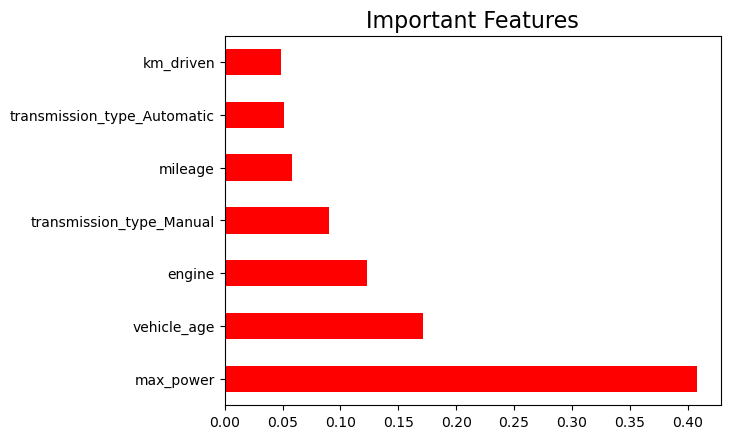

In [191]:
imp_feature=pd.Series(model.feature_importances_,index= X.columns)
imp_feature.nlargest(7).plot(kind='barh',color='red')
plt.title('Important Features', fontsize=16)
plt.show()

# 10.Model Building & Evaluation

## Train-Test Split

In [192]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=3)

## Importing Important libaries for Model Building

In [193]:
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,explained_variance_score,r2_score

In [194]:
models= [LinearRegression,SVR,DecisionTreeRegressor,RandomForestRegressor,Ridge,Lasso]
mse=[]
rmse=[]
evs=[]
r_square_score=[]

for model in models:
    regressor=model().fit(X_train,y_train)
    pred=regressor.predict(X_test)
    mse.append(mean_squared_error(y_true=y_test,y_pred=pred))
    rmse.append(np.sqrt(mean_squared_error(y_test,y_pred=pred)))
    evs.append(explained_variance_score(y_true=y_test,y_pred=pred))
    r_square_score.append(r2_score(y_true=y_test,y_pred=pred))

## Creating DataFrame for Model Comparision

In [195]:
ML_model_df=pd.DataFrame({"Model":['Linear Regression','Support Vector Regression','Decision Tree Regression',\
                          'Random Forest Regreessor','Ridge','Lasso'],
                          "Mean Squared Error":mse,
                          "Root Mean Squared Error":evs,
                          "R-Square Score(Accuracy)":r_square_score})

ML_model_df.set_index('Model',inplace=True)
ML_model_df

,Mean Squared Error,Root Mean Squared Error,R-Square Score(Accuracy)
Model,,,
Linear Regression,2.185960e+11,6.852785e-01,0.685090
Support Vector Regression,7.411809e+11,6.465838e-10,-0.067747
Decision Tree Regression,1.094006e+11,8.424022e-01,0.842397
Random Forest Regreessor,5.678599e+10,9.182400e-01,0.918194
Ridge,2.185927e+11,6.852836e-01,0.685095
Lasso,2.185952e+11,6.852798e-01,0.685091


# Selection of Best Model & Hyperprameter Tuning

In [196]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, explained_variance_score, r2_score
import numpy as np

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True, False]
}

# Initialize the Random Forest Regressor
rf = RandomForestRegressor(random_state=42)

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=10,          # Reduced from 100 to 10
    cv=2,               # Reduced from 3 to 2
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Fit the model
random_search.fit(X_train, y_train)

# Best model
best_rf = random_search.best_estimator_

# Predictions
y_pred = best_rf.predict(X_test)

# Evaluation Metrics
mse_rf = mean_squared_error(y_test, y_pred)
rmse_rf = np.sqrt(mse_rf)
evs_rf = explained_variance_score(y_test, y_pred)
r2_rf = r2_score(y_test, y_pred)

# Store the results
mse.append(mse_rf)
rmse.append(rmse_rf)
evs.append(evs_rf)
r_square_score.append(r2_rf)

# Print results
print("Best Hyperparameters:", random_search.best_params_)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest Explained Variance Score:", evs_rf)
print("Random Forest R² Score:", r2_rf)

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Best Hyperparameters: {'n_estimators': 150, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 30, 'bootstrap': False}
Random Forest MSE: 41918519340.86308
Random Forest RMSE: 204740.1263574463
Random Forest Explained Variance Score: 0.939646713831779
Random Forest R² Score: 0.9396120615980712


# Generating Pickle File-saving

In [210]:
import pickle

saved_models = []

for model_class in models:
    model = model_class()
    regressor = model.fit(X_train, y_train)

    # Save the trained model to a pickle file
    model_filename = f"{model_class.__name__}_model.pkl"

    with open(model_filename, "wb") as model_file:
        pickle.dump(regressor, model_file)

    saved_models.append(model_filename)

print(saved_models)


['LinearRegression_model.pkl', 'SVR_model.pkl', 'DecisionTreeRegressor_model.pkl', 'RandomForestRegressor_model.pkl', 'Ridge_model.pkl', 'Lasso_model.pkl']


In [217]:
saved_models

['LinearRegression_model.pkl',
 'SVR_model.pkl',
 'DecisionTreeRegressor_model.pkl',
 'RandomForestRegressor_model.pkl',
 'Ridge_model.pkl',
 'Lasso_model.pkl']

In [218]:
best_rf 
model_filename=f"best_model.pkl"
with open(model_filename,"wb") as model_file:
    pickle.dump(best_rf,model_file)

In [219]:
import pickle
model = pickle.load(open(model_filename, "rb"))
print(model)

RandomForestRegressor(bootstrap=False, max_depth=30, max_features='sqrt',
                      min_samples_split=5, n_estimators=150, random_state=42)


In [220]:
X_test.iloc[4:7,:]

,min_cost_price,max_cost_price,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
15428,40000,39500000,9,90000,11.57,2179,138.1,7,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
7147,40000,39500000,5,71205,21.40,1197,83.1,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2493,40000,39500000,10,108800,12.80,2494,102.0,7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [227]:
d= [[5,71205,21.40,1197,83.1,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0]]

In [236]:
array= [[9,90000,11.57,2179,138.1,7,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0]]

In [237]:
model.predict(array)

array([328680.])

In [223]:
print(X.columns)

Index(['min_cost_price', 'max_cost_price', 'vehicle_age', 'km_driven',
       'mileage', 'engine', 'max_power', 'seats', 'seller_type_Dealer',
       'seller_type_Individual', 'seller_type_Trustmark Dealer',
       'fuel_type_CNG', 'fuel_type_Diesel', 'fuel_type_Electric',
       'fuel_type_LPG', 'fuel_type_Petrol', 'transmission_type_Automatic',
       'transmission_type_Manual'],
      dtype='object')


In [224]:
X = X.drop(['min_cost_price', 'max_cost_price'], axis=1)

In [225]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)
model.fit(X, y)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [226]:
import pickle

pickle.dump(model, open("best_model.pkl", "wb"))